In [2]:
from pathlib import Path
import pandas as pd

# Folder containing the notebook and CSV files
data_dir = Path(".")

datasets = {}

for file in sorted(data_dir.glob("Kashkadarya_Field_Indices_*.csv")):
    year = int(file.stem.split("_")[-1])
    datasets[year] = pd.read_csv(file)

print(f"Loaded files: {len(datasets)}")

for year, df in sorted(datasets.items()):
    print(f"{year}: {len(df)} rows, {len(df.columns)} columns")

Loaded files: 9
2017: 426 rows, 60 columns
2018: 426 rows, 60 columns
2019: 426 rows, 60 columns
2020: 426 rows, 60 columns
2021: 426 rows, 60 columns
2022: 426 rows, 60 columns
2023: 426 rows, 60 columns
2024: 426 rows, 60 columns
2025: 426 rows, 60 columns


In [3]:
# Phase 2 — Field ID consistency check

id_col = "system:index"

reference_year = min(datasets.keys())
reference_ids = set(datasets[reference_year][id_col])

print(f"Reference year: {reference_year}")
print(f"Reference field IDs: {len(reference_ids)}")
print()

for year, df in sorted(datasets.items()):
    ids = set(df[id_col])

    missing = reference_ids - ids
    extra = ids - reference_ids
    duplicates = df[id_col].duplicated().sum()

    print(f"{year}:")
    print(f"  Rows: {len(df)}")
    print(f"  Unique IDs: {df[id_col].nunique()}")
    print(f"  Duplicate IDs: {duplicates}")
    print(f"  Missing IDs: {len(missing)}")
    print(f"  Extra IDs: {len(extra)}")

Reference year: 2017
Reference field IDs: 426

2017:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0
2018:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0
2019:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0
2020:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0
2021:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0
2022:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0
2023:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0
2024:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0
2025:
  Rows: 426
  Unique IDs: 426
  Duplicate IDs: 0
  Missing IDs: 0
  Extra IDs: 0


In [4]:
# Phase 2 — Static attribute consistency check

id_col = "system:index"

static_cols = [
    "area",
    "label_1",
    "label_2",
    "year",
    "region",
    "country",
    "sampler"
]

reference_year = min(datasets.keys())
reference_df = datasets[reference_year][[id_col] + static_cols].copy()

print(f"Reference year: {reference_year}")
print()

for year, df in sorted(datasets.items()):

    current_df = df[[id_col] + static_cols].copy()

    merged = reference_df.merge(
        current_df,
        on=id_col,
        suffixes=("_ref", "_cur")
    )

    differences = {}

    for col in static_cols:

        if col == "area":
            mask = (
                (merged[f"{col}_ref"] - merged[f"{col}_cur"]).abs() > 0.01
            )
        else:
            mask = (
                merged[f"{col}_ref"].astype(str)
                != merged[f"{col}_cur"].astype(str)
            )

        differences[col] = mask.sum()

    total_diff = sum(differences.values())

    print(f"{year}: total attribute differences = {total_diff}")

    for col, count in differences.items():
        if count > 0:
            print(f"  {col}: {count}")

Reference year: 2017

2017: total attribute differences = 0
2018: total attribute differences = 0
2019: total attribute differences = 0
2020: total attribute differences = 0
2021: total attribute differences = 0
2022: total attribute differences = 0
2023: total attribute differences = 0
2024: total attribute differences = 0
2025: total attribute differences = 0


In [5]:
# Phase 2 — Year, region, and monthly observation-count column check

for year, df in sorted(datasets.items()):

    count_cols = [
        col for col in df.columns
        if col.endswith("_scene_count") or col.endswith("_image_count")
    ]

    print(f"{year}:")
    print(f"  observation_year: {df['observation_year'].unique()}")
    print(f"  reference year (year): {df['year'].unique()}")
    print(f"  region: {df['region'].unique()}")
    print(f"  scene_count columns: {len([c for c in count_cols if c.endswith('_scene_count')])}")
    print(f"  image_count columns: {len([c for c in count_cols if c.endswith('_image_count')])}")
    print()

2017:
  observation_year: [2017]
  reference year (year): [2018]
  region: ['Kashkadarya']
  scene_count columns: 12
  image_count columns: 0

2018:
  observation_year: [2018]
  reference year (year): [2018]
  region: ['Kashkadarya']
  scene_count columns: 12
  image_count columns: 0

2019:
  observation_year: [2019]
  reference year (year): [2018]
  region: ['Kashkadarya']
  scene_count columns: 12
  image_count columns: 0

2020:
  observation_year: [2020]
  reference year (year): [2018]
  region: ['Kashkadarya']
  scene_count columns: 12
  image_count columns: 0

2021:
  observation_year: [2021]
  reference year (year): [2018]
  region: ['Kashkadarya']
  scene_count columns: 12
  image_count columns: 0

2022:
  observation_year: [2022]
  reference year (year): [2018]
  region: ['Kashkadarya']
  scene_count columns: 12
  image_count columns: 0

2023:
  observation_year: [2023]
  reference year (year): [2018]
  region: ['Kashkadarya']
  scene_count columns: 12
  image_count columns: 0


In [6]:
# Check monthly observation-count column structure for all years

for year, df in sorted(datasets.items()):
    scene_cols = [c for c in df.columns if c.endswith("_scene_count")]
    image_cols = [c for c in df.columns if c.endswith("_image_count")]

    print(
        f"{year}: "
        f"scene_count={len(scene_cols)}, "
        f"image_count={len(image_cols)}"
    )

2017: scene_count=12, image_count=0
2018: scene_count=12, image_count=0
2019: scene_count=12, image_count=0
2020: scene_count=12, image_count=0
2021: scene_count=12, image_count=0
2022: scene_count=12, image_count=0
2023: scene_count=12, image_count=0
2024: scene_count=12, image_count=0
2025: scene_count=12, image_count=0


In [7]:
# Phase 3 — Monthly scene availability by year

rows = []

for year, df in sorted(datasets.items()):

    for month in range(1, 13):

        col = f"m{month:02d}_scene_count"

        rows.append({
            "year": year,
            "month": month,
            "mean_scene_count": df[col].mean(),
            "median_scene_count": df[col].median(),
            "min_scene_count": df[col].min(),
            "max_scene_count": df[col].max(),
            "pct_low_obs": (df[col] < 2).mean() * 100
        })

scene_qc = pd.DataFrame(rows)

scene_qc

,year,month,mean_scene_count,median_scene_count,min_scene_count,max_scene_count,pct_low_obs
0,2017,1,2.0,2.0,2.0,2.0,0.0
1,2017,2,2.0,2.0,2.0,2.0,0.0
2,2017,3,4.0,4.0,4.0,4.0,0.0
3,2017,4,4.0,4.0,4.0,4.0,0.0
4,2017,5,0.0,0.0,0.0,0.0,100.0
...,...,...,...,...,...,...,...
103,2025,8,30.0,30.0,30.0,30.0,0.0
104,2025,9,28.0,28.0,28.0,28.0,0.0
105,2025,10,28.0,28.0,28.0,28.0,0.0
106,2025,11,33.0,33.0,33.0,33.0,0.0


In [8]:
# Phase 3 — Valid growing-season months per field and year

growing_months = range(4, 11)  # April–October

rows = []

for year, df in sorted(datasets.items()):

    for _, row in df.iterrows():

        valid_months = 0

        for month in growing_months:

            ndvi_col = f"m{month:02d}_NDVI"
            scene_col = f"m{month:02d}_scene_count"

            # A valid month requires:
            # 1. At least 2 scenes
            # 2. A non-missing NDVI value
            if (
                row[scene_col] >= 2
                and pd.notna(row[ndvi_col])
            ):
                valid_months += 1

        rows.append({
            "field_id": row["system:index"],
            "year": year,
            "n_valid_months": valid_months
        })

valid_months_df = pd.DataFrame(rows)

# Annual field-level validity rule:
# at least 5 valid growing-season months
valid_months_df["annual_metric_eligible"] = (
    valid_months_df["n_valid_months"] >= 5
)

# Summary by year
year_summary = (
    valid_months_df
    .groupby("year")
    .agg(
        total_fields=("field_id", "nunique"),
        fields_with_5plus_valid_months=("annual_metric_eligible", "sum"),
        min_valid_months=("n_valid_months", "min"),
        median_valid_months=("n_valid_months", "median"),
        max_valid_months=("n_valid_months", "max")
    )
    .reset_index()
)

year_summary["pct_fields_eligible"] = (
    year_summary["fields_with_5plus_valid_months"]
    / year_summary["total_fields"]
    * 100
)

year_summary["year_pass"] = (
    year_summary["pct_fields_eligible"] >= 80
)

year_summary

,year,total_fields,fields_with_5plus_valid_months,min_valid_months,median_valid_months,max_valid_months,pct_fields_eligible,year_pass
0,2017,426,426,6,6.0,6,100.0,True
1,2018,426,426,7,7.0,7,100.0,True
2,2019,426,426,7,7.0,7,100.0,True
3,2020,426,426,7,7.0,7,100.0,True
4,2021,426,426,7,7.0,7,100.0,True
5,2022,426,426,7,7.0,7,100.0,True
6,2023,426,426,7,7.0,7,100.0,True
7,2024,426,426,7,7.0,7,100.0,True
8,2025,426,426,7,7.0,7,100.0,True


In [9]:
# Phase 3 — Check scene_count variability across fields

# 1. Check how many different scene_count values exist
# for each month within each year.

for year, df in sorted(datasets.items()):
    print(f"\nYear {year}")

    for month in range(1, 13):
        col = f"m{month:02d}_scene_count"
        print(
            f"  {col}: "
            f"nunique={df[col].nunique()}, "
            f"values={sorted(df[col].dropna().unique().tolist())}"
        )


# 2. Display the complete year × month scene_count summary
print("\nYear × Month Scene Count Summary:")

scene_qc.sort_values(["year", "month"])


Year 2017
  m01_scene_count: nunique=1, values=[2.0]
  m02_scene_count: nunique=1, values=[2.0]
  m03_scene_count: nunique=1, values=[4.0]
  m04_scene_count: nunique=1, values=[4.0]
  m05_scene_count: nunique=1, values=[0.0]
  m06_scene_count: nunique=1, values=[5.0]
  m07_scene_count: nunique=1, values=[12.0]
  m08_scene_count: nunique=1, values=[20.0]
  m09_scene_count: nunique=1, values=[14.0]
  m10_scene_count: nunique=1, values=[14.0]
  m11_scene_count: nunique=1, values=[10.0]
  m12_scene_count: nunique=1, values=[9.0]

Year 2018
  m01_scene_count: nunique=1, values=[6.0]
  m02_scene_count: nunique=1, values=[2.0]
  m03_scene_count: nunique=1, values=[5.0]
  m04_scene_count: nunique=1, values=[4.0]
  m05_scene_count: nunique=1, values=[4.0]
  m06_scene_count: nunique=1, values=[10.0]
  m07_scene_count: nunique=1, values=[4.0]
  m08_scene_count: nunique=1, values=[4.0]
  m09_scene_count: nunique=1, values=[4.0]
  m10_scene_count: nunique=1, values=[6.0]
  m11_scene_count: nunique

,year,month,mean_scene_count,median_scene_count,min_scene_count,max_scene_count,pct_low_obs
0,2017,1,2.0,2.0,2.0,2.0,0.0
1,2017,2,2.0,2.0,2.0,2.0,0.0
2,2017,3,4.0,4.0,4.0,4.0,0.0
3,2017,4,4.0,4.0,4.0,4.0,0.0
4,2017,5,0.0,0.0,0.0,0.0,100.0
...,...,...,...,...,...,...,...
103,2025,8,30.0,30.0,30.0,30.0,0.0
104,2025,9,28.0,28.0,28.0,28.0,0.0
105,2025,10,28.0,28.0,28.0,28.0,0.0
106,2025,11,33.0,33.0,33.0,33.0,0.0


In [10]:
# Phase 3 — Sensitivity check for scene-count threshold

for threshold in [2, 3]:

    print(f"\nScene-count threshold: >= {threshold}")

    for year in sorted(datasets.keys()):

        valid_months = 0

        for month in range(4, 11):  # April–October
            col = f"m{month:02d}_scene_count"

            # Because scene_count is cluster-level,
            # the value is identical across all fields.
            scene_count = datasets[year][col].iloc[0]

            if scene_count >= threshold:
                valid_months += 1

        print(
            f"{year}: "
            f"{valid_months}/7 valid growing-season months"
        )


Scene-count threshold: >= 2
2017: 6/7 valid growing-season months
2018: 7/7 valid growing-season months
2019: 7/7 valid growing-season months
2020: 7/7 valid growing-season months
2021: 7/7 valid growing-season months
2022: 7/7 valid growing-season months
2023: 7/7 valid growing-season months
2024: 7/7 valid growing-season months
2025: 7/7 valid growing-season months

Scene-count threshold: >= 3
2017: 6/7 valid growing-season months
2018: 7/7 valid growing-season months
2019: 7/7 valid growing-season months
2020: 7/7 valid growing-season months
2021: 7/7 valid growing-season months
2022: 7/7 valid growing-season months
2023: 7/7 valid growing-season months
2024: 7/7 valid growing-season months
2025: 7/7 valid growing-season months


In [11]:
# Phase 4 preparation — create field_geometry_qc from the CSV geometry

import json
import geopandas as gpd
from shapely.geometry import shape

# Use 2017 as the reference dataset because geometry/static attributes
# are expected to be identical across all years.
ref = datasets[2017].copy()

# Convert .geo JSON strings to Shapely geometries
ref["geometry"] = ref[".geo"].apply(
    lambda x: shape(json.loads(x))
)

# Create GeoDataFrame in geographic CRS
gdf = gpd.GeoDataFrame(
    ref[
        [
            "system:index",
            "area",
            "label_1",
            "label_2",
            "year",
            "region",
            "geometry"
        ]
    ].copy(),
    geometry="geometry",
    crs="EPSG:4326"
)

# Reproject to UTM for area calculation
gdf_utm = gdf.to_crs(gdf.estimate_utm_crs())

# Calculate geometry area
gdf_utm["geom_area_m2"] = gdf_utm.geometry.area

# Calculate relative area difference
gdf_utm["area_diff_pct"] = (
    abs(gdf_utm["geom_area_m2"] - gdf_utm["area"])
    / gdf_utm["area"]
    * 100
)

# Rename system:index to field_id
field_geometry_qc = gdf_utm.rename(
    columns={
        "system:index": "field_id",
        "year": "reference_year"
    }
)

# Keep only required QC columns
field_geometry_qc = field_geometry_qc[
    [
        "field_id",
        "area",
        "geom_area_m2",
        "area_diff_pct",
        "label_1",
        "label_2",
        "reference_year",
        "region",
        "geometry"
    ]
].copy()

print("Fields:", len(field_geometry_qc))
print("Unique field IDs:", field_geometry_qc["field_id"].nunique())
print("Duplicate field IDs:", field_geometry_qc["field_id"].duplicated().sum())
print("Maximum area difference (%):", field_geometry_qc["area_diff_pct"].max())
print("Minimum field area (ha):", field_geometry_qc["geom_area_m2"].min() / 10000)

Fields: 426
Unique field IDs: 426
Duplicate field IDs: 0
Maximum area difference (%): 0.5469280100183426
Minimum field area (ha): 0.7435917878628404


In [12]:
# Final Phase 1 geometry QC check

flagged = field_geometry_qc[
    field_geometry_qc["area_diff_pct"] > 5
]

print(f"Fields with area difference > 5%: {len(flagged)}")

if len(flagged) > 0:
    print(flagged[
        ["field_id", "area", "geom_area_m2", "area_diff_pct"]
    ])

Fields with area difference > 5%: 0


In [13]:
# Phase 4 — Convert annual wide-format data to long format

long_parts = []

for year, df in sorted(datasets.items()):

    temp = df.copy()

    # Rename field identifier
    temp = temp.rename(columns={"system:index": "field_id"})

    # Create one row per field-month
    for month in range(1, 13):

        month_str = f"{month:02d}"

        month_df = temp[
            [
                "field_id",
                f"m{month_str}_NDVI",
                f"m{month_str}_NDMI",
                f"m{month_str}_EVI",
                f"m{month_str}_scene_count"
            ]
        ].copy()

        month_df["year"] = year
        month_df["month"] = month

        month_df = month_df.rename(
            columns={
                f"m{month_str}_NDVI": "NDVI",
                f"m{month_str}_NDMI": "NDMI",
                f"m{month_str}_EVI": "EVI",
                f"m{month_str}_scene_count": "scene_count"
            }
        )

        long_parts.append(month_df)


# Combine all years and months
field_monthly_long = pd.concat(
    long_parts,
    ignore_index=True
)

# Add 2018 reference crop label and final geometry area
geometry_attributes = field_geometry_qc[
    [
        "field_id",
        "label_1",
        "geom_area_m2"
    ]
].copy()

geometry_attributes = geometry_attributes.rename(
    columns={
        "label_1": "crop_label_2018",
        "geom_area_m2": "area_m2"
    }
)

field_monthly_long = field_monthly_long.merge(
    geometry_attributes,
    on="field_id",
    how="left",
    validate="many_to_one"
)

# Reorder columns
field_monthly_long = field_monthly_long[
    [
        "field_id",
        "year",
        "month",
        "NDVI",
        "NDMI",
        "EVI",
        "scene_count",
        "crop_label_2018",
        "area_m2"
    ]
]

print("Rows:", len(field_monthly_long))
print("Columns:", len(field_monthly_long.columns))
print("Unique fields:", field_monthly_long["field_id"].nunique())
print("Years:", sorted(field_monthly_long["year"].unique()))
print("Months:", sorted(field_monthly_long["month"].unique()))

field_monthly_long.head()

Rows: 46008
Columns: 9
Unique fields: 426
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Months: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


,field_id,year,month,NDVI,NDMI,EVI,scene_count,crop_label_2018,area_m2
0,000000000000000000ee,2017,1,NaN,NaN,NaN,2.0,wheat-other,8308.417435
1,0000000000000000016f,2017,1,NaN,NaN,NaN,2.0,wheat-other,76652.578707
2,0000000000000000003e,2017,1,NaN,NaN,NaN,2.0,fallow,41902.749487
3,000000000000000000d3,2017,1,NaN,NaN,NaN,2.0,fallow,24902.374535
4,000000000000000000d6,2017,1,NaN,NaN,NaN,2.0,fallow,74727.329309


In [14]:
# Phase 4 — Check geometry attribute join

print("Missing crop_label_2018:", field_monthly_long["crop_label_2018"].isna().sum())
print("Missing area_m2:", field_monthly_long["area_m2"].isna().sum())

print("Expected rows:", 426 * 9 * 12)
print("Actual rows:", len(field_monthly_long))

Missing crop_label_2018: 0
Missing area_m2: 0
Expected rows: 46008
Actual rows: 46008


In [15]:
# Phase 5 — Observation QC
# Check missing values and index ranges

print("Missing values:")
print(field_monthly_long[["NDVI", "NDMI", "EVI"]].isna().sum())

print("\nNDVI range:")
print(
    field_monthly_long["NDVI"].min(),
    field_monthly_long["NDVI"].max()
)

print("\nNDMI range:")
print(
    field_monthly_long["NDMI"].min(),
    field_monthly_long["NDMI"].max()
)

print("\nEVI range:")
print(
    field_monthly_long["EVI"].min(),
    field_monthly_long["EVI"].max()
)

Missing values:
NDVI    847
NDMI    847
EVI     847
dtype: int64

NDVI range:
-0.0341342589566598 0.936600613128426

NDMI range:
-0.2500549082607172 0.8585163480804866

EVI range:
-0.010310730125657 0.9196679300024616


In [16]:
# Phase 5 — Missing-value distribution by year and month

missing_qc = (
    field_monthly_long
    .groupby(["year", "month"])
    .agg(
        total_records=("field_id", "size"),
        missing_NDVI=("NDVI", "count"),
        missing_NDMI=("NDMI", "count"),
        missing_EVI=("EVI", "count")
    )
    .reset_index()
)

# Convert counts to actual missing values
missing_qc["missing_NDVI"] = (
    missing_qc["total_records"] - missing_qc["missing_NDVI"]
)

missing_qc["missing_NDMI"] = (
    missing_qc["total_records"] - missing_qc["missing_NDMI"]
)

missing_qc["missing_EVI"] = (
    missing_qc["total_records"] - missing_qc["missing_EVI"]
)

missing_qc

,year,month,total_records,missing_NDVI,missing_NDMI,missing_EVI
0,2017,1,426,421,421,421
1,2017,2,426,0,0,0
2,2017,3,426,0,0,0
3,2017,4,426,0,0,0
4,2017,5,426,426,426,426
...,...,...,...,...,...,...
103,2025,8,426,0,0,0
104,2025,9,426,0,0,0
105,2025,10,426,0,0,0
106,2025,11,426,0,0,0


In [17]:
# Phase 5 — Missing values during the growing season

growing_missing = missing_qc[
    missing_qc["month"].between(4, 10)
].copy()

growing_missing

,year,month,total_records,missing_NDVI,missing_NDMI,missing_EVI
3,2017,4,426,0,0,0
4,2017,5,426,426,426,426
5,2017,6,426,0,0,0
6,2017,7,426,0,0,0
7,2017,8,426,0,0,0
...,...,...,...,...,...,...
101,2025,6,426,0,0,0
102,2025,7,426,0,0,0
103,2025,8,426,0,0,0
104,2025,9,426,0,0,0


In [18]:
# Phase 5 — Check for values outside expected index ranges

print("NDVI outside [-1, 1]:",
      ((field_monthly_long["NDVI"] < -1) |
       (field_monthly_long["NDVI"] > 1)).sum())

print("NDMI outside [-1, 1]:",
      ((field_monthly_long["NDMI"] < -1) |
       (field_monthly_long["NDMI"] > 1)).sum())

print("EVI outside [-1, 1]:",
      ((field_monthly_long["EVI"] < -1) |
       (field_monthly_long["EVI"] > 1)).sum())

NDVI outside [-1, 1]: 0
NDMI outside [-1, 1]: 0
EVI outside [-1, 1]: 0


In [19]:
# Phase 5 — Create observation QC flags

field_monthly_long["low_obs"] = (
    field_monthly_long["scene_count"] < 2
)

field_monthly_long["is_valid_month"] = (
    field_monthly_long["NDVI"].notna()
    & (field_monthly_long["scene_count"] >= 2)
)

print("Total records:", len(field_monthly_long))
print("Low-observation records:", field_monthly_long["low_obs"].sum())
print("Valid monthly records:", field_monthly_long["is_valid_month"].sum())

print("\nInvalid growing-season records:")
print(
    field_monthly_long[
        field_monthly_long["month"].between(4, 10)
        & ~field_monthly_long["is_valid_month"]
    ][
        ["year", "month", "scene_count", "NDVI"]
    ].drop_duplicates()
)

Total records: 46008
Low-observation records: 426
Valid monthly records: 45161

Invalid growing-season records:
      year  month  scene_count  NDVI
1704  2017      5          0.0   NaN


In [20]:
# Phase 6 — Check remaining missing values by field and year

missing_by_field_year = (
    field_monthly_long[
        field_monthly_long["month"].between(4, 10)
        & field_monthly_long["NDVI"].isna()
    ]
    .groupby(["field_id", "year"])
    .size()
    .reset_index(name="missing_growing_months")
)

print("Field-year combinations with missing growing-season months:")
print(len(missing_by_field_year))

print("\nMissing months by year:")
print(
    missing_by_field_year
    .groupby("year")["missing_growing_months"]
    .value_counts()
)

Field-year combinations with missing growing-season months:
426

Missing months by year:
year  missing_growing_months
2017  1                         426
Name: count, dtype: int64


In [21]:
# Phase 7 — Annual / seasonal field metrics

# Keep only the growing season
gs = field_monthly_long[
    field_monthly_long["month"].between(4, 10)
].copy()

# Keep only real, valid monthly observations
gs_valid = gs[
    gs["is_valid_month"]
].copy()

annual_metrics = (
    gs_valid
    .groupby(["field_id", "year"])
    .agg(
        NDVI_mean_gs=("NDVI", "mean"),
        NDVI_max=("NDVI", "max"),
        peak_month=("NDVI", lambda x: gs_valid.loc[x.idxmax(), "month"]),
        n_valid_months=("NDVI", "count")
    )
    .reset_index()
)

# Annual metric eligibility
annual_metrics["metric_eligible"] = (
    annual_metrics["n_valid_months"] >= 5
)

print("Rows:", len(annual_metrics))
print("Unique fields:", annual_metrics["field_id"].nunique())
print("\nValid months by year:")
print(
    annual_metrics
    .groupby("year")["n_valid_months"]
    .agg(["min", "median", "max"])
)

print("\nAnnual metrics:")
annual_metrics.head()

Rows: 3834
Unique fields: 426

Valid months by year:
      min  median  max
year                  
2017    6     6.0    6
2018    7     7.0    7
2019    7     7.0    7
2020    7     7.0    7
2021    7     7.0    7
2022    7     7.0    7
2023    7     7.0    7
2024    7     7.0    7
2025    7     7.0    7

Annual metrics:


,field_id,year,NDVI_mean_gs,NDVI_max,peak_month,n_valid_months,metric_eligible
0,00000000000000000000,2017,0.553139,0.710133,9,6,True
1,00000000000000000000,2018,0.418551,0.521483,8,7,True
2,00000000000000000000,2019,0.461549,0.628403,4,7,True
3,00000000000000000000,2020,0.468662,0.713281,7,7,True
4,00000000000000000000,2021,0.366883,0.623564,8,7,True


In [22]:
# Phase 7 — Complete annual / seasonal metrics

annual_extra = (
    gs_valid
    .groupby(["field_id", "year"])
    .agg(
        NDVI_integral=("NDVI", "sum"),
        NDMI_mean_gs=("NDMI", "mean"),
        NDMI_max=("NDMI", "max"),
        EVI_mean_gs=("EVI", "mean"),
        EVI_max=("EVI", "max")
    )
    .reset_index()
)

annual_metrics = annual_metrics.merge(
    annual_extra,
    on=["field_id", "year"],
    how="left",
    validate="one_to_one"
)

print("Rows:", len(annual_metrics))
print("Columns:", len(annual_metrics.columns))

annual_metrics.head()

Rows: 3834
Columns: 12


,field_id,year,NDVI_mean_gs,NDVI_max,peak_month,n_valid_months,metric_eligible,NDVI_integral,NDMI_mean_gs,NDMI_max,EVI_mean_gs,EVI_max
0,00000000000000000000,2017,0.553139,0.710133,9,6,True,3.318834,0.191772,0.300470,0.441112,0.591419
1,00000000000000000000,2018,0.418551,0.521483,8,7,True,2.929859,0.114302,0.187979,0.321232,0.414052
2,00000000000000000000,2019,0.461549,0.628403,4,7,True,3.230844,0.134850,0.249532,0.377729,0.518025
3,00000000000000000000,2020,0.468662,0.713281,7,7,True,3.280636,0.139851,0.303822,0.379821,0.603039
4,00000000000000000000,2021,0.366883,0.623564,8,7,True,2.568184,0.090355,0.277671,0.293641,0.515654


In [23]:
# Phase 7 — Basic distribution check of annual metrics

metrics = [
    "NDVI_mean_gs",
    "NDVI_max",
    "NDVI_integral",
    "NDMI_mean_gs",
    "NDMI_max",
    "EVI_mean_gs",
    "EVI_max"
]

annual_metrics[metrics].describe().T

,count,mean,std,min,25%,50%,75%,max
NDVI_mean_gs,3834.0,0.361315,0.076789,0.115721,0.312000,0.356049,0.404022,0.735812
NDVI_max,3834.0,0.636842,0.124088,0.156891,0.554096,0.647204,0.723690,0.936601
NDVI_integral,3834.0,2.484078,0.516180,0.810046,2.160069,2.469514,2.780273,4.945855
NDMI_mean_gs,3834.0,0.110337,0.042591,-0.047571,0.084598,0.109182,0.136119,0.286764
NDMI_max,3834.0,0.295928,0.087845,-0.019658,0.234419,0.295599,0.357676,0.547936
EVI_mean_gs,3834.0,0.291253,0.064040,0.089381,0.251046,0.285688,0.325764,0.614767
EVI_max,3834.0,0.526696,0.113097,0.130209,0.449355,0.526460,0.603193,0.919668


In [24]:
# Phase 8 — Field-level NDVI trend analysis

from scipy.stats import theilslopes
import pymannkendall as mk
from statsmodels.stats.multitest import multipletests

trend_results = []

for field_id, group in annual_metrics.groupby("field_id"):

    group = group.sort_values("year")

    x = group["year"].to_numpy()
    y = group["NDVI_mean_gs"].to_numpy()

    # Theil–Sen slope
    sen_result = theilslopes(y, x)

    # Mann–Kendall test
    mk_result = mk.original_test(y)

    trend_results.append({
        "field_id": field_id,
        "sen_slope": sen_result.slope,
        "mk_p": mk_result.p,
        "mk_trend": mk_result.trend
    })

trend_results = pd.DataFrame(trend_results)

# Benjamini–Hochberg correction
reject, q_values, _, _ = multipletests(
    trend_results["mk_p"],
    alpha=0.05,
    method="fdr_bh"
)

trend_results["q_value"] = q_values
trend_results["significant"] = reject

# Fixed practical slope threshold
trend_results["slope_threshold_met"] = (
    trend_results["sen_slope"].abs() >= 0.005
)

print("Fields analysed:", len(trend_results))
print("\nSignificant after BH correction:",
      trend_results["significant"].sum())

print("\nFields meeting slope threshold:",
      trend_results["slope_threshold_met"].sum())

trend_results.head()

Fields analysed: 426

Significant after BH correction: 0

Fields meeting slope threshold: 259


,field_id,sen_slope,mk_p,mk_trend,q_value,significant,slope_threshold_met
0,00000000000000000000,0.005241,0.916965,no trend,0.986432,False,True
1,00000000000000000001,-0.004527,0.602168,no trend,0.939646,False,False
2,00000000000000000002,-0.001207,0.754454,no trend,0.970989,False,False
3,00000000000000000003,-0.003593,0.602168,no trend,0.939646,False,False
4,00000000000000000004,-0.011148,0.348083,no trend,0.797221,False,True


In [25]:
# Phase 9 — Field-level variability

field_cv = (
    annual_metrics
    .groupby("field_id")["NDVI_mean_gs"]
    .agg(["mean", "std"])
    .reset_index()
)

field_cv["CV"] = (
    field_cv["std"] / field_cv["mean"].abs()
)

print(field_cv["CV"].describe())

print("\nFields with missing CV:",
      field_cv["CV"].isna().sum())

count    426.000000
mean       0.174767
std        0.055246
min        0.053637
25%        0.137437
50%        0.169490
75%        0.204991
max        0.426992
Name: CV, dtype: float64

Fields with missing CV: 0


In [26]:
# Phase 9 — Define high-variability threshold

cv_threshold = field_cv["CV"].quantile(0.75)

print(f"High-variability CV threshold: {cv_threshold:.6f}")

high_var_count = (
    field_cv["CV"] >= cv_threshold
).sum()

print(f"Fields classified as high variability: {high_var_count}")
print(f"Percentage: {high_var_count / len(field_cv) * 100:.1f}%")

High-variability CV threshold: 0.204991
Fields classified as high variability: 107
Percentage: 25.1%


In [27]:
# Phase 9 — Final field classification

# Merge trend results with variability results
field_classification = trend_results.merge(
    field_cv[["field_id", "CV"]],
    on="field_id",
    how="inner",
    validate="one_to_one"
)

# Fixed thresholds
q_threshold = 0.05
slope_threshold = 0.005
cv_threshold = 0.204991

# Classification
def classify_field(row):

    # Priority 1: High variability
    if row["CV"] >= cv_threshold:
        return "High variability"

    # Priority 2: Increasing
    if (
        row["q_value"] < q_threshold
        and row["sen_slope"] >= slope_threshold
    ):
        return "Increasing NDVI"

    # Priority 3: Declining
    if (
        row["q_value"] < q_threshold
        and row["sen_slope"] <= -slope_threshold
    ):
        return "Declining NDVI"

    # Remaining fields
    return "Stable"

field_classification["category"] = (
    field_classification.apply(classify_field, axis=1)
)

# Summary
category_summary = (
    field_classification["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="fields")
)

category_summary["percentage"] = (
    category_summary["fields"]
    / len(field_classification)
    * 100
)

category_summary

,category,fields,percentage
0,Stable,319,74.882629
1,High variability,107,25.117371


In [28]:
# Phase 10 — NDMI / EVI consistency check

from scipy.stats import theilslopes, spearmanr

consistency_results = []

for field_id, group in annual_metrics.groupby("field_id"):

    group = group.sort_values("year")

    x = group["year"].to_numpy()

    ndvi = group["NDVI_mean_gs"].to_numpy()
    ndmi = group["NDMI_mean_gs"].to_numpy()
    evi = group["EVI_mean_gs"].to_numpy()

    ndvi_slope = theilslopes(ndvi, x).slope
    ndmi_slope = theilslopes(ndmi, x).slope
    evi_slope = theilslopes(evi, x).slope

    consistency_results.append({
        "field_id": field_id,
        "NDVI_slope": ndvi_slope,
        "NDMI_slope": ndmi_slope,
        "EVI_slope": evi_slope
    })

consistency_results = pd.DataFrame(consistency_results)

# Correlation of field-level slopes
ndvi_ndmi_corr, ndvi_ndmi_p = spearmanr(
    consistency_results["NDVI_slope"],
    consistency_results["NDMI_slope"]
)

ndvi_evi_corr, ndvi_evi_p = spearmanr(
    consistency_results["NDVI_slope"],
    consistency_results["EVI_slope"]
)

print("NDVI slope vs NDMI slope:")
print(f"Spearman rho = {ndvi_ndmi_corr:.3f}")
print(f"p-value = {ndvi_ndmi_p:.4f}")

print("\nNDVI slope vs EVI slope:")
print(f"Spearman rho = {ndvi_evi_corr:.3f}")
print(f"p-value = {ndvi_evi_p:.4f}")

print("\nConsistency results:")
consistency_results.head()

NDVI slope vs NDMI slope:
Spearman rho = 0.902
p-value = 0.0000

NDVI slope vs EVI slope:
Spearman rho = 0.969
p-value = 0.0000

Consistency results:


,field_id,NDVI_slope,NDMI_slope,EVI_slope
0,00000000000000000000,0.005241,0.003783,0.006215
1,00000000000000000001,-0.004527,-0.003448,0.001019
2,00000000000000000002,-0.001207,0.000287,0.001392
3,00000000000000000003,-0.003593,0.002131,0.000174
4,00000000000000000004,-0.011148,-0.009130,-0.010433


In [29]:
# Phase 11 — Check 2018 reference crop classes

crop_counts_2018 = (
    field_monthly_long[
        (field_monthly_long["year"] == 2018)
        & (field_monthly_long["month"].between(4, 10))
    ]
    .groupby("crop_label_2018")["field_id"]
    .nunique()
    .sort_values(ascending=False)
)

crop_counts_2018

crop_label_2018
cotton         221
wheat          177
orchard         15
alfalfa          4
fallow           3
maize            2
vineyard         2
wheat-other      2
Name: field_id, dtype: int64

In [30]:
# Phase 11 — Group rare 2018 crop classes into "Other"

crop_profile = field_monthly_long[
    (field_monthly_long["year"] == 2018)
    & (field_monthly_long["month"].between(4, 10))
].copy()

major_crops = ["cotton", "wheat", "orchard"]

crop_profile["crop_class"] = crop_profile["crop_label_2018"].where(
    crop_profile["crop_label_2018"].isin(major_crops),
    "Other"
)

print(
    crop_profile
    .groupby("crop_class")["field_id"]
    .nunique()
    .sort_values(ascending=False)
)

crop_class
cotton     221
wheat      177
orchard     15
Other       13
Name: field_id, dtype: int64


In [31]:
# Phase 11 — 2018 seasonal NDVI profiles by reference crop class

profile = (
    crop_profile
    .groupby(["crop_class", "month"])["NDVI"]
    .mean()
    .reset_index()
)

profile

,crop_class,month,NDVI
0,Other,4,0.368474
1,Other,5,0.364578
2,Other,6,0.404016
3,Other,7,0.383504
4,Other,8,0.435526
5,Other,9,0.341721
6,Other,10,0.285222
7,cotton,4,0.096692
8,cotton,5,0.100071
9,cotton,6,0.160575


In [32]:
# Phase 11 — Check whether any field has more than one crop label

crop_label_check = (
    crop_profile
    .groupby("field_id")["crop_label_2018"]
    .nunique()
)

print("Fields with more than one crop label:",
      (crop_label_check > 1).sum())

if (crop_label_check > 1).sum() > 0:
    problematic_fields = crop_label_check[crop_label_check > 1]
    print(problematic_fields)

Fields with more than one crop label: 0


In [33]:
# Phase 11 — Recheck crop-label counts

print("Total unique fields:",
      crop_profile["field_id"].nunique())

print("\nCrop counts:")
print(
    crop_profile
    .groupby("crop_label_2018")["field_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nSum of crop counts:",
      crop_profile
      .groupby("crop_label_2018")["field_id"]
      .nunique()
      .sum())

Total unique fields: 426

Crop counts:
crop_label_2018
cotton         221
wheat          177
orchard         15
alfalfa          4
fallow           3
maize            2
vineyard         2
wheat-other      2
Name: field_id, dtype: int64

Sum of crop counts: 426


In [34]:
# Phase 11 — 2018 seasonal NDVI profile

profile = (
    crop_profile
    .groupby(["crop_class", "month"])["NDVI"]
    .mean()
    .reset_index()
)

profile

,crop_class,month,NDVI
0,Other,4,0.368474
1,Other,5,0.364578
2,Other,6,0.404016
3,Other,7,0.383504
4,Other,8,0.435526
5,Other,9,0.341721
6,Other,10,0.285222
7,cotton,4,0.096692
8,cotton,5,0.100071
9,cotton,6,0.160575


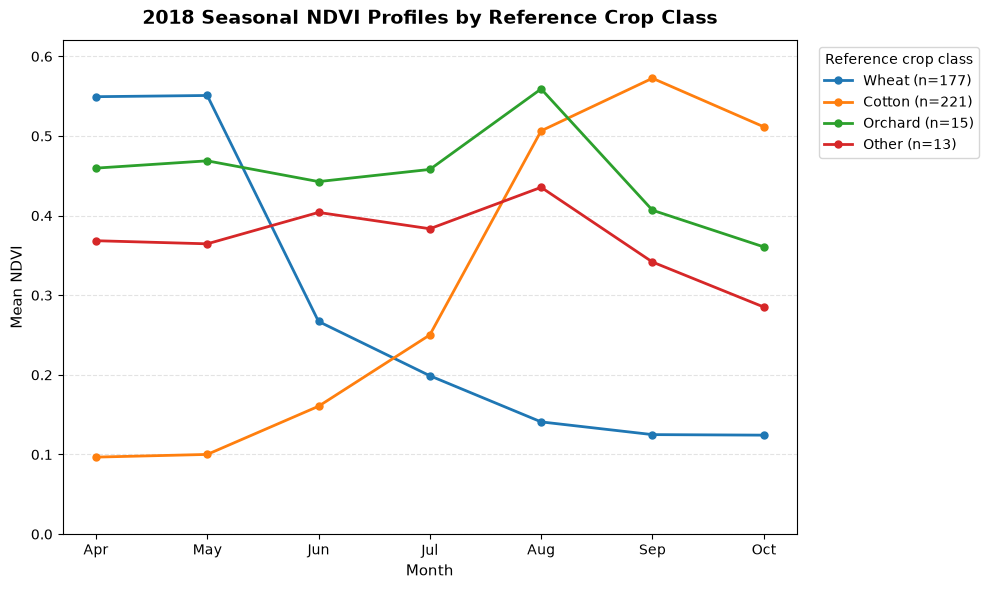

In [35]:
# Phase 11 — 2018 seasonal NDVI profiles by reference crop class

import matplotlib.pyplot as plt

# Number of fields in each reference crop class
crop_n = (
    crop_profile.groupby("crop_class")["field_id"]
    .nunique()
    .to_dict()
)

# Month labels
month_labels = {
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct"
}

# Create plot
plt.figure(figsize=(10, 6))

for crop in ["wheat", "cotton", "orchard", "Other"]:

    crop_data = (
        profile[profile["crop_class"] == crop]
        .sort_values("month")
    )

    plt.plot(
        crop_data["month"],
        crop_data["NDVI"],
        marker="o",
        linewidth=2,
        markersize=5,
        label=f"{crop.capitalize()} (n={crop_n[crop]})"
    )

# X-axis
plt.xticks(
    list(month_labels.keys()),
    list(month_labels.values())
)

# Axis labels
plt.xlabel("Month", fontsize=11)
plt.ylabel("Mean NDVI", fontsize=11)

# Title
plt.title(
    "2018 Seasonal NDVI Profiles by Reference Crop Class",
    fontsize=14,
    fontweight="bold",
    pad=12
)

# Y-axis range
plt.ylim(0, 0.62)

# Grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

# Legend
plt.legend(
    title="Reference crop class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True
)

# Layout
plt.tight_layout()

# Display
plt.show()

In [36]:
# Check slope direction by 2018 reference crop class

slope_check = trend_results.merge(
    field_geometry_qc[["field_id", "label_1"]],
    on="field_id",
    how="left",
    validate="one_to_one"
)

# Keep only fields with |Sen slope| >= 0.005
slope_check = slope_check[
    slope_check["sen_slope"].abs() >= 0.005
].copy()

# Define slope direction
slope_check["slope_direction"] = slope_check["sen_slope"].apply(
    lambda x: "Positive" if x > 0 else "Negative"
)

# Summary by crop and slope direction
slope_by_crop = pd.crosstab(
    slope_check["label_1"],
    slope_check["slope_direction"]
)

# Add total
slope_by_crop["Total"] = slope_by_crop.sum(axis=1)

print("Fields with |Sen slope| >= 0.005:",
      len(slope_check))

print("\nSlope direction by 2018 reference crop:")
slope_by_crop

Fields with |Sen slope| >= 0.005: 259

Slope direction by 2018 reference crop:


slope_direction,Negative,Positive,Total
label_1,,,
alfalfa,2,1,3
cotton,84,40,124
fallow,0,2,2
maize,1,1,2
orchard,10,1,11
vineyard,0,2,2
wheat,81,33,114
wheat-other,1,0,1


In [37]:
# Check slope-by-crop table consistency

print("Rows in slope_check:", len(slope_check))
print("Unique fields:", slope_check["field_id"].nunique())

print("\nMissing crop labels:",
      slope_check["label_1"].isna().sum())

print("\nFields by crop and direction:")
print(
    slope_check
    .groupby(["label_1", "slope_direction"])["field_id"]
    .nunique()
    .unstack(fill_value=0)
)

print("\nTotal unique fields by crop:")
print(
    slope_check
    .groupby("label_1")["field_id"]
    .nunique()
)

Rows in slope_check: 259
Unique fields: 259

Missing crop labels: 0

Fields by crop and direction:
slope_direction  Negative  Positive
label_1                            
alfalfa                 2         1
cotton                 84        40
fallow                  0         2
maize                   1         1
orchard                10         1
vineyard                0         2
wheat                  81        33
wheat-other             1         0

Total unique fields by crop:
label_1
alfalfa          3
cotton         124
fallow           2
maize            2
orchard         11
vineyard         2
wheat          114
wheat-other      1
Name: field_id, dtype: int64


In [38]:
# Sensitivity analysis — common growing-season months
# Use the same six months for every year:
# April + June + July + August + September + October

common_months = [4, 6, 7, 8, 9, 10]

annual_metrics_common = (
    field_monthly_long[
        field_monthly_long["month"].isin(common_months)
        & field_monthly_long["is_valid_month"]
    ]
    .groupby(["field_id", "year"])
    .agg(
        NDVI_mean_gs_common=("NDVI", "mean"),
        n_valid_months_common=("NDVI", "count")
    )
    .reset_index()
)

print("Rows:", len(annual_metrics_common))
print("Unique fields:",
      annual_metrics_common["field_id"].nunique())

print("\nValid months by year:")
print(
    annual_metrics_common
    .groupby("year")["n_valid_months_common"]
    .agg(["min", "median", "max"])
)

annual_metrics_common.head()

Rows: 3834
Unique fields: 426

Valid months by year:
      min  median  max
year                  
2017    6     6.0    6
2018    6     6.0    6
2019    6     6.0    6
2020    6     6.0    6
2021    6     6.0    6
2022    6     6.0    6
2023    6     6.0    6
2024    6     6.0    6
2025    6     6.0    6


,field_id,year,NDVI_mean_gs_common,n_valid_months_common
0,00000000000000000000,2017,0.553139,6
1,00000000000000000000,2018,0.435020,6
2,00000000000000000000,2019,0.467056,6
3,00000000000000000000,2020,0.478359,6
4,00000000000000000000,2021,0.394632,6


In [39]:
# Phase 8 — Sensitivity trend analysis using common months

trend_common = []

for field_id, group in annual_metrics_common.groupby("field_id"):

    group = group.sort_values("year")

    x = group["year"].to_numpy()
    y = group["NDVI_mean_gs_common"].to_numpy()

    # Theil–Sen slope
    sen_result = theilslopes(y, x)

    # Mann–Kendall test
    mk_result = mk.original_test(y)

    trend_common.append({
        "field_id": field_id,
        "sen_slope_common": sen_result.slope,
        "mk_p_common": mk_result.p
    })

trend_common = pd.DataFrame(trend_common)

# Benjamini–Hochberg correction
reject, q_values, _, _ = multipletests(
    trend_common["mk_p_common"],
    alpha=0.05,
    method="fdr_bh"
)

trend_common["q_value_common"] = q_values
trend_common["significant_common"] = reject

# Practical slope threshold
trend_common["slope_threshold_met_common"] = (
    trend_common["sen_slope_common"].abs() >= 0.005
)

print("Fields analysed:", len(trend_common))
print(
    "Significant after BH:",
    trend_common["significant_common"].sum()
)
print(
    "Fields meeting slope threshold:",
    trend_common["slope_threshold_met_common"].sum()
)

Fields analysed: 426
Significant after BH: 0
Fields meeting slope threshold: 264


In [40]:
# Phase 8 — Sensitivity analysis excluding 2017

trend_no2017 = []

for field_id, group in annual_metrics_common.groupby("field_id"):

    group = group[
        group["year"] >= 2018
    ].sort_values("year")

    x = group["year"].to_numpy()
    y = group["NDVI_mean_gs_common"].to_numpy()

    sen_result = theilslopes(y, x)
    mk_result = mk.original_test(y)

    trend_no2017.append({
        "field_id": field_id,
        "sen_slope_no2017": sen_result.slope,
        "mk_p_no2017": mk_result.p
    })

trend_no2017 = pd.DataFrame(trend_no2017)

# Benjamini–Hochberg correction
reject, q_values, _, _ = multipletests(
    trend_no2017["mk_p_no2017"],
    alpha=0.05,
    method="fdr_bh"
)

trend_no2017["q_value_no2017"] = q_values
trend_no2017["significant_no2017"] = reject

trend_no2017["slope_threshold_met_no2017"] = (
    trend_no2017["sen_slope_no2017"].abs() >= 0.005
)

print("Fields analysed:", len(trend_no2017))
print(
    "Significant after BH:",
    trend_no2017["significant_no2017"].sum()
)
print(
    "Fields meeting slope threshold:",
    trend_no2017["slope_threshold_met_no2017"].sum()
)

Fields analysed: 426
Significant after BH: 0
Fields meeting slope threshold: 290


In [41]:
# Phase 9 — Final variability and field classification
# Based on the common-month NDVI metric

# Calculate field-level CV using the common-month metric
field_cv_common = (
    annual_metrics_common
    .groupby("field_id")["NDVI_mean_gs_common"]
    .agg(["mean", "std"])
    .reset_index()
)

field_cv_common["CV"] = (
    field_cv_common["std"]
    / field_cv_common["mean"].abs()
)

# High-variability threshold: upper quartile
cv_threshold_common = field_cv_common["CV"].quantile(0.75)

print(f"High-variability CV threshold: {cv_threshold_common:.6f}")

# Merge trend results with CV
field_classification_final = trend_common.merge(
    field_cv_common[["field_id", "CV"]],
    on="field_id",
    how="inner",
    validate="one_to_one"
)

# Fixed thresholds
q_threshold = 0.05
slope_threshold = 0.005

# Classification
def classify_field(row):

    # Priority 1: High variability
    if row["CV"] >= cv_threshold_common:
        return "High variability"

    # Priority 2: Increasing
    if (
        row["q_value_common"] < q_threshold
        and row["sen_slope_common"] >= slope_threshold
    ):
        return "Increasing NDVI"

    # Priority 3: Declining
    if (
        row["q_value_common"] < q_threshold
        and row["sen_slope_common"] <= -slope_threshold
    ):
        return "Declining NDVI"

    # Remaining fields
    return "No detectable trend"

field_classification_final["category"] = (
    field_classification_final.apply(
        classify_field,
        axis=1
    )
)

# Category summary
category_summary_final = (
    field_classification_final["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="fields")
)

category_summary_final["percentage"] = (
    category_summary_final["fields"]
    / len(field_classification_final)
    * 100
)

category_summary_final

High-variability CV threshold: 0.255638


,category,fields,percentage
0,No detectable trend,319,74.882629
1,High variability,107,25.117371


In [42]:
# Phase 9 — Final category by 2018 reference crop

category_crop = field_classification_final.merge(
    field_geometry_qc[["field_id", "label_1"]],
    on="field_id",
    how="left",
    validate="one_to_one"
)

category_crop["crop_class"] = category_crop["label_1"].where(
    category_crop["label_1"].isin(["cotton", "wheat", "orchard"]),
    "Other"
)

category_crop_table = pd.crosstab(
    category_crop["crop_class"],
    category_crop["category"]
)

category_crop_table

category,High variability,No detectable trend
crop_class,,
Other,6,7
cotton,29,192
orchard,0,15
wheat,72,105


In [43]:
# Phase 11 — Peak month by 2018 reference crop class

peak_month_check = (
    profile
    .loc[
        profile.groupby("crop_class")["NDVI"].idxmax()
    ]
    [
        ["crop_class", "month", "NDVI"]
    ]
    .sort_values("crop_class")
)

peak_month_check

,crop_class,month,NDVI
4,Other,8,0.435526
12,cotton,9,0.572502
18,orchard,8,0.559122
22,wheat,5,0.550873


In [44]:
# Cluster-level annual NDVI signal

cluster_ndvi = (
    annual_metrics_common
    .groupby("year")["NDVI_mean_gs_common"]
    .median()
    .reset_index(name="median_NDVI")
)

cluster_ndvi

,year,median_NDVI
0,2017,0.419131
1,2018,0.300072
2,2019,0.405105
3,2020,0.408780
4,2021,0.349063
5,2022,0.369997
6,2023,0.330988
7,2024,0.377694
8,2025,0.359858


In [45]:
# Recalculate field-level CV using the corrected common-month metric

field_cv_final = (
    annual_metrics_common
    .groupby("field_id")["NDVI_mean_gs_common"]
    .agg(["mean", "std"])
    .reset_index()
)

field_cv_final["CV"] = (
    field_cv_final["std"]
    / field_cv_final["mean"].abs()
)

cv_threshold_final = field_cv_final["CV"].quantile(0.75)

print(f"CV threshold (75th percentile): {cv_threshold_final:.6f}")

print(
    "High-variability fields:",
    (field_cv_final["CV"] >= cv_threshold_final).sum()
)

print(
    "Fields with missing CV:",
    field_cv_final["CV"].isna().sum()
)

field_cv_final["high_variability"] = (
    field_cv_final["CV"] >= cv_threshold_final
)

# Add 2018 reference crop class
cv_crop = field_cv_final.merge(
    field_geometry_qc[["field_id", "label_1"]],
    on="field_id",
    how="left",
    validate="one_to_one"
)

cv_crop["crop_class"] = cv_crop["label_1"].where(
    cv_crop["label_1"].isin(["cotton", "wheat", "orchard"]),
    "Other"
)

# Count high-variability fields by crop
cv_crop_summary = (
    cv_crop
    .groupby("crop_class")
    .agg(
        fields=("field_id", "nunique"),
        high_variability=("high_variability", "sum")
    )
    .reset_index()
)

cv_crop_summary["high_variability_pct"] = (
    cv_crop_summary["high_variability"]
    / cv_crop_summary["fields"]
    * 100
)

cv_crop_summary

CV threshold (75th percentile): 0.255638
High-variability fields: 107
Fields with missing CV: 0


,crop_class,fields,high_variability,high_variability_pct
0,Other,13,6,46.153846
1,cotton,221,29,13.122172
2,orchard,15,0,0.000000
3,wheat,177,72,40.677966


In [46]:
# Restore the main project datasets after kernel restart

from pathlib import Path
import pandas as pd
import geopandas as gpd
import json
from shapely.geometry import shape

data_dir = Path(".")

# -----------------------------
# 1. Load annual CSV datasets
# -----------------------------

datasets = {}

for file in sorted(data_dir.glob("Kashkadarya_Field_Indices_*.csv")):
    year = int(file.stem.split("_")[-1])
    datasets[year] = pd.read_csv(file)

print("Loaded annual datasets:")
for year, df in sorted(datasets.items()):
    print(f"{year}: {len(df)} rows, {len(df.columns)} columns")


# -----------------------------
# 2. Create field_monthly_long
# -----------------------------

long_parts = []

for year, df in sorted(datasets.items()):

    temp = df.copy()
    temp = temp.rename(columns={"system:index": "field_id"})

    for month in range(1, 13):

        m = f"{month:02d}"

        month_df = temp[
            [
                "field_id",
                f"m{m}_NDVI",
                f"m{m}_NDMI",
                f"m{m}_EVI",
                f"m{m}_scene_count"
            ]
        ].copy()

        month_df["year"] = year
        month_df["month"] = month

        month_df = month_df.rename(
            columns={
                f"m{m}_NDVI": "NDVI",
                f"m{m}_NDMI": "NDMI",
                f"m{m}_EVI": "EVI",
                f"m{m}_scene_count": "scene_count"
            }
        )

        long_parts.append(month_df)

field_monthly_long = pd.concat(
    long_parts,
    ignore_index=True
)


# --------------------------------
# 3. Restore field geometry table
# --------------------------------

ref = datasets[2017].copy()

ref["geometry"] = ref[".geo"].apply(
    lambda x: shape(json.loads(x))
)

gdf = gpd.GeoDataFrame(
    ref[
        [
            "system:index",
            "area",
            "label_1",
            "label_2",
            "year",
            "region",
            "geometry"
        ]
    ].copy(),
    geometry="geometry",
    crs="EPSG:4326"
)

gdf_utm = gdf.to_crs(gdf.estimate_utm_crs())

gdf_utm["geom_area_m2"] = gdf_utm.geometry.area

gdf_utm["area_diff_pct"] = (
    abs(gdf_utm["geom_area_m2"] - gdf_utm["area"])
    / gdf_utm["area"]
    * 100
)

field_geometry_qc = gdf_utm.rename(
    columns={
        "system:index": "field_id",
        "year": "reference_year"
    }
)

field_geometry_qc = field_geometry_qc[
    [
        "field_id",
        "area",
        "geom_area_m2",
        "area_diff_pct",
        "label_1",
        "label_2",
        "reference_year",
        "region",
        "geometry"
    ]
].copy()


# -----------------------------
# 4. Restore monthly QC flag
# -----------------------------

field_monthly_long["low_obs"] = (
    field_monthly_long["scene_count"] < 2
)

field_monthly_long["is_valid_month"] = (
    field_monthly_long["NDVI"].notna()
    & (field_monthly_long["scene_count"] >= 2)
)


# -----------------------------
# 5. Check restoration
# -----------------------------

print("\nRestoration complete.")

print("Long table rows:", len(field_monthly_long))
print("Unique fields:", field_monthly_long["field_id"].nunique())
print("Geometry fields:", len(field_geometry_qc))

Loaded annual datasets:
2017: 426 rows, 60 columns
2018: 426 rows, 60 columns
2019: 426 rows, 60 columns
2020: 426 rows, 60 columns
2021: 426 rows, 60 columns
2022: 426 rows, 60 columns
2023: 426 rows, 60 columns
2024: 426 rows, 60 columns
2025: 426 rows, 60 columns

Restoration complete.
Long table rows: 46008
Unique fields: 426
Geometry fields: 426


In [47]:
# Diagnostic check:
# CV using the full April–October metric for 2018–2025

annual_2018_2025 = (
    field_monthly_long[
        (field_monthly_long["year"] >= 2018)
        & (field_monthly_long["month"].between(4, 10))
        & (field_monthly_long["is_valid_month"])
    ]
    .groupby(["field_id", "year"])
    .agg(
        NDVI_mean_gs=("NDVI", "mean")
    )
    .reset_index()
)

# Calculate field-level CV
cv_full_7m = (
    annual_2018_2025
    .groupby("field_id")["NDVI_mean_gs"]
    .agg(["mean", "std"])
    .reset_index()
)

cv_full_7m["CV"] = (
    cv_full_7m["std"]
    / cv_full_7m["mean"].abs()
)

# Add 2018 reference crop
cv_full_7m = cv_full_7m.merge(
    field_geometry_qc[["field_id", "label_1"]],
    on="field_id",
    how="left",
    validate="one_to_one"
)

cv_full_7m["crop_class"] = cv_full_7m["label_1"].where(
    cv_full_7m["label_1"].isin(["cotton", "wheat", "orchard"]),
    "Other"
)

# Summary by crop
cv_full_summary = (
    cv_full_7m
    .groupby("crop_class")
    .agg(
        fields=("field_id", "nunique"),
        mean_CV=("CV", "mean"),
        median_CV=("CV", "median")
    )
    .reset_index()
)

print("CV using full April–October metric, 2018–2025:")
print(cv_full_summary)

print("\nOverall CV distribution:")
print(cv_full_7m["CV"].describe())

CV using full April–October metric, 2018–2025:
  crop_class  fields   mean_CV  median_CV
0      Other      13  0.215371   0.230478
1     cotton     221  0.155076   0.152640
2    orchard      15  0.130148   0.135679
3      wheat     177  0.173769   0.170151

Overall CV distribution:
count    426.000000
mean       0.163805
std        0.057395
min        0.055630
25%        0.122903
50%        0.159201
75%        0.194312
max        0.457997
Name: CV, dtype: float64


In [48]:
# Diagnostic check:
# Compare NDVI_max variability across 2018–2025

annual_max_2018_2025 = (
    field_monthly_long[
        (field_monthly_long["year"] >= 2018)
        & (field_monthly_long["month"].between(4, 10))
        & (field_monthly_long["is_valid_month"])
    ]
    .groupby(["field_id", "year"])
    .agg(
        NDVI_max=("NDVI", "max")
    )
    .reset_index()
)

max_cv = (
    annual_max_2018_2025
    .groupby("field_id")["NDVI_max"]
    .agg(["mean", "std"])
    .reset_index()
)

max_cv["CV"] = (
    max_cv["std"]
    / max_cv["mean"].abs()
)

max_cv = max_cv.merge(
    field_geometry_qc[["field_id", "label_1"]],
    on="field_id",
    how="left",
    validate="one_to_one"
)

max_cv["crop_class"] = max_cv["label_1"].where(
    max_cv["label_1"].isin(["cotton", "wheat", "orchard"]),
    "Other"
)

max_cv_summary = (
    max_cv
    .groupby("crop_class")
    .agg(
        fields=("field_id", "nunique"),
        mean_CV=("CV", "mean"),
        median_CV=("CV", "median")
    )
    .reset_index()
)

print("NDVI_max CV, 2018–2025:")
print(max_cv_summary)

print("\nOverall NDVI_max CV distribution:")
print(max_cv["CV"].describe())

NDVI_max CV, 2018–2025:
  crop_class  fields   mean_CV  median_CV
0      Other      13  0.191804   0.191483
1     cotton     221  0.168950   0.159532
2    orchard      15  0.153152   0.139591
3      wheat     177  0.172374   0.162354

Overall NDVI_max CV distribution:
count    426.000000
mean       0.170514
std        0.060774
min        0.049919
25%        0.125157
50%        0.160057
75%        0.207978
max        0.390978
Name: CV, dtype: float64


In [49]:
# Diagnostic check — 2017 vs 2018 and stricter scene threshold

common_months = [4, 6, 7, 8, 9, 10]

# ---------------------------------------------------
# 1. Compare 2017 and 2018 using the same 6 months
# ---------------------------------------------------

comparison = (
    field_monthly_long[
        field_monthly_long["month"].isin(common_months)
        & field_monthly_long["is_valid_month"]
        & field_monthly_long["year"].isin([2017, 2018])
    ]
    .groupby(["field_id", "year"])["NDVI"]
    .mean()
    .unstack()
    .reset_index()
)

comparison["NDVI_2018_lower"] = (
    comparison[2018] < comparison[2017]
)

# Add 2018 reference crop
comparison = comparison.merge(
    field_geometry_qc[["field_id", "label_1"]],
    on="field_id",
    how="left",
    validate="one_to_one"
)

comparison["crop_class"] = comparison["label_1"].where(
    comparison["label_1"].isin(["cotton", "wheat", "orchard"]),
    "Other"
)

print("2018 lower than 2017:")
print(
    comparison["NDVI_2018_lower"].mean() * 100
)

print("\nBy 2018 reference crop:")
print(
    comparison
    .groupby("crop_class")["NDVI_2018_lower"]
    .agg(["count", "mean"])
    .assign(percent_2018_lower=lambda x: x["mean"] * 100)
)

# ---------------------------------------------------
# 2. Stricter scene-count threshold: >= 5
# ---------------------------------------------------

print("\nGrowing-season months with scene_count >= 5:")

for year in range(2017, 2026):

    valid_months = 0

    for month in range(4, 11):

        col = f"m{month:02d}_scene_count"
        scene_count = datasets[year][col].iloc[0]

        if scene_count >= 5:
            valid_months += 1

    print(f"{year}: {valid_months}/7 months")

2018 lower than 2017:
79.81220657276995

By 2018 reference crop:
            count      mean  percent_2018_lower
crop_class                                     
Other          13  0.615385           61.538462
cotton        221  0.669683           66.968326
orchard        15  0.933333           93.333333
wheat         177  0.960452           96.045198

Growing-season months with scene_count >= 5:
2017: 5/7 months
2018: 2/7 months
2019: 7/7 months
2020: 7/7 months
2021: 7/7 months
2022: 7/7 months
2023: 7/7 months
2024: 7/7 months
2025: 7/7 months


In [50]:
from pathlib import Path
import pandas as pd

# Use the current Jupyter working directory
data_dir = Path.cwd()

# Climate CSV files
era5_file = data_dir / "Kashkadarya_ERA5Land_Climate_2017_2025.csv"
chirps_file = data_dir / "Kashkadarya_CHIRPS_Precipitation_2017_2025.csv"

# Load climate datasets
era5_climate = pd.read_csv(era5_file)
chirps_precip = pd.read_csv(chirps_file)

# Basic inspection
print("ERA5-Land shape:", era5_climate.shape)
print("CHIRPS shape:", chirps_precip.shape)

print("\nERA5-Land columns:")
print(era5_climate.columns.tolist())

print("\nCHIRPS columns:")
print(chirps_precip.columns.tolist())

print("\nERA5-Land:")
display(era5_climate)

print("\nCHIRPS:")
display(chirps_precip)

ERA5-Land shape: (9, 11)
CHIRPS shape: (9, 8)

ERA5-Land columns:
['system:index', 'mean_relative_humidity_apr_oct_pct', 'mean_temp_apr_oct_C', 'mean_wind_10m_mps', 'n_era5_cells', 'n_months', 'potential_evaporation_apr_oct_mm', 'potential_evaporation_raw_apr_oct_m', 'solar_radiation_apr_oct_MJ_m2', 'year', '.geo']

CHIRPS columns:
['system:index', 'n_chirps_cells', 'n_days_apr_oct', 'n_days_oct_apr', 'precip_apr_oct_mm', 'precip_oct_apr_mm', 'year', '.geo']

ERA5-Land:


,system:index,mean_relative_humidity_apr_oct_pct,mean_temp_apr_oct_C,mean_wind_10m_mps,n_era5_cells,n_months,potential_evaporation_apr_oct_mm,potential_evaporation_raw_apr_oct_m,solar_radiation_apr_oct_MJ_m2,year,.geo
0,0,35.974429,24.209456,1.528154,2,7,2175.706501,-2.175707,5059.957050,2017.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1,31.444965,24.251161,1.581080,2,7,2270.467976,-2.270468,4953.017998,2018.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,2,40.057934,23.700672,1.384397,2,7,2057.759493,-2.057759,4907.328506,2019.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,3,39.566310,22.780465,1.044220,2,7,1901.897339,-1.901897,4909.084842,2020.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,4,30.885719,24.745080,1.495729,2,7,2250.192153,-2.250192,5132.682005,2021.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
5,5,35.507953,24.903254,1.611017,2,7,2186.932008,-2.186932,5034.822039,2022.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
6,6,28.025408,25.822480,1.747287,2,7,2456.660621,-2.456661,5096.184427,2023.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
7,7,33.973685,24.989168,1.580459,2,7,2246.917320,-2.246917,4868.466912,2024.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
8,8,25.693593,26.976351,1.852359,2,7,2576.764876,-2.576765,5144.338588,2025.0,"{""type"":""MultiPoint"",""coordinates"":[]}"



CHIRPS:


,system:index,n_chirps_cells,n_days_apr_oct,n_days_oct_apr,precip_apr_oct_mm,precip_oct_apr_mm,year,.geo
0,0,8,214,212,40.211326,246.860851,2017.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1,8,214,212,56.153461,141.148529,2018.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,2,8,214,212,120.862011,354.400810,2019.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,3,8,214,213,100.847936,213.722287,2020.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,4,8,214,212,15.837981,149.865780,2021.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
5,5,8,214,212,50.390435,188.810233,2022.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
6,6,8,214,212,25.308861,137.329367,2023.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
7,7,8,214,213,58.842604,196.667524,2024.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
8,8,8,214,212,29.360183,161.721752,2025.0,"{""type"":""MultiPoint"",""coordinates"":[]}"


In [51]:
# ============================================================
# PHASE 12 — Build annual NDVI and merge climate data
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Build common-month annual NDVI directly from
#    field_monthly_long
#
# Common months:
# April, June, July, August, September, October
# May is excluded for ALL years because May 2017 has no scenes.
# ------------------------------------------------------------

common_months = [4, 6, 7, 8, 9, 10]

ndvi_common = field_monthly_long[
    field_monthly_long["month"].isin(common_months)
].copy()

# Field-year mean NDVI across the six common months
field_year_ndvi = (
    ndvi_common
    .groupby(["field_id", "year"], as_index=False)["NDVI"]
    .mean()
    .rename(columns={"NDVI": "NDVI_mean_gs_common"})
)

# Cluster-level annual median across 426 fields
ndvi_annual = (
    field_year_ndvi
    .groupby("year", as_index=False)["NDVI_mean_gs_common"]
    .median()
    .rename(columns={"NDVI_mean_gs_common": "median_NDVI"})
)

# ------------------------------------------------------------
# 2. Clean climate year fields
# ------------------------------------------------------------

era5_climate["year"] = era5_climate["year"].astype(int)
chirps_precip["year"] = chirps_precip["year"].astype(int)

# ------------------------------------------------------------
# 3. Keep analytical ERA5-Land variables
# ------------------------------------------------------------

era5_main = era5_climate[
    [
        "year",
        "mean_temp_apr_oct_C",
        "mean_wind_10m_mps",
        "mean_relative_humidity_apr_oct_pct",
        "solar_radiation_apr_oct_MJ_m2",
        "potential_evaporation_apr_oct_mm",
        "n_era5_cells",
        "n_months"
    ]
].copy()

# ------------------------------------------------------------
# 4. Keep analytical CHIRPS variables
# ------------------------------------------------------------

chirps_main = chirps_precip[
    [
        "year",
        "precip_oct_apr_mm",
        "precip_apr_oct_mm",
        "n_chirps_cells",
        "n_days_oct_apr",
        "n_days_apr_oct"
    ]
].copy()

# ------------------------------------------------------------
# 5. Merge ERA5-Land + CHIRPS
# ------------------------------------------------------------

climate_annual = pd.merge(
    era5_main,
    chirps_main,
    on="year",
    how="inner",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 6. Merge climate with annual median NDVI
# ------------------------------------------------------------

climate_ndvi = pd.merge(
    ndvi_annual,
    climate_annual,
    on="year",
    how="inner",
    validate="one_to_one"
)

# Sort chronologically
climate_ndvi = (
    climate_ndvi
    .sort_values("year")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 7. Basic validation
# ------------------------------------------------------------

expected_years = list(range(2017, 2026))

assert climate_ndvi["year"].tolist() == expected_years, \
    "Year coverage is not exactly 2017–2025."

print("Final table shape:", climate_ndvi.shape)

print("\nYears:")
print(climate_ndvi["year"].tolist())

print("\nMissing values:")
print(climate_ndvi.isna().sum())

print("\nAnnual cluster-level NDVI:")
display(ndvi_annual)

print("\nFinal climate–NDVI table:")
display(climate_ndvi)

Final table shape: (9, 14)

Years:
[2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

Missing values:
year                                  0
median_NDVI                           0
mean_temp_apr_oct_C                   0
mean_wind_10m_mps                     0
mean_relative_humidity_apr_oct_pct    0
solar_radiation_apr_oct_MJ_m2         0
potential_evaporation_apr_oct_mm      0
n_era5_cells                          0
n_months                              0
precip_oct_apr_mm                     0
precip_apr_oct_mm                     0
n_chirps_cells                        0
n_days_oct_apr                        0
n_days_apr_oct                        0
dtype: int64

Annual cluster-level NDVI:


,year,median_NDVI
0,2017,0.419131
1,2018,0.300072
2,2019,0.405105
3,2020,0.408780
4,2021,0.349063
5,2022,0.369997
6,2023,0.330988
7,2024,0.377694
8,2025,0.359858



Final climate–NDVI table:


,year,median_NDVI,mean_temp_apr_oct_C,mean_wind_10m_mps,mean_relative_humidity_apr_oct_pct,solar_radiation_apr_oct_MJ_m2,potential_evaporation_apr_oct_mm,n_era5_cells,n_months,precip_oct_apr_mm,precip_apr_oct_mm,n_chirps_cells,n_days_oct_apr,n_days_apr_oct
0,2017,0.419131,24.209456,1.528154,35.974429,5059.957050,2175.706501,2,7,246.860851,40.211326,8,212,214
1,2018,0.300072,24.251161,1.581080,31.444965,4953.017998,2270.467976,2,7,141.148529,56.153461,8,212,214
2,2019,0.405105,23.700672,1.384397,40.057934,4907.328506,2057.759493,2,7,354.400810,120.862011,8,212,214
3,2020,0.408780,22.780465,1.044220,39.566310,4909.084842,1901.897339,2,7,213.722287,100.847936,8,213,214
4,2021,0.349063,24.745080,1.495729,30.885719,5132.682005,2250.192153,2,7,149.865780,15.837981,8,212,214
5,2022,0.369997,24.903254,1.611017,35.507953,5034.822039,2186.932008,2,7,188.810233,50.390435,8,212,214
6,2023,0.330988,25.822480,1.747287,28.025408,5096.184427,2456.660621,2,7,137.329367,25.308861,8,212,214
7,2024,0.377694,24.989168,1.580459,33.973685,4868.466912,2246.917320,2,7,196.667524,58.842604,8,213,214
8,2025,0.359858,26.976351,1.852359,25.693593,5144.338588,2576.764876,2,7,161.721752,29.360183,8,212,214


In [52]:
# ============================================================
# PROJECT 1 — PHASE 12
# Climate–NDVI Data Integration
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

required_objects = [
    "field_monthly_long",
    "era5_climate",
    "chirps_precip"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise NameError(
        f"Missing required objects: {missing_objects}"
    )

print("Required data objects are available.")


# ============================================================
# 2. BUILD COMMON-GROWING-SEASON NDVI
# ============================================================
#
# Common months used for all years:
# April, June, July, August, September, October
#
# May is excluded for all years because May 2017 has no
# Sentinel-2 observations at the study-cluster level.
#
# Step 1:
# Calculate field-year mean NDVI.
#
# Step 2:
# Calculate annual median across fields.
#
# Final indicator:
# NDVI = annual median of field-level common-season NDVI
# ============================================================

common_months = [4, 6, 7, 8, 9, 10]

ndvi_common = field_monthly_long[
    field_monthly_long["month"].isin(common_months)
].copy()

print(
    "Common-season records:",
    len(ndvi_common)
)


# Field-year mean NDVI
field_year_ndvi = (
    ndvi_common
    .groupby(
        ["field_id", "year"],
        as_index=False
    )["NDVI"]
    .mean()
    .rename(
        columns={
            "NDVI": "NDVI_mean_common"
        }
    )
)


# Annual cluster-level median NDVI
ndvi_annual = (
    field_year_ndvi
    .groupby(
        "year",
        as_index=False
    )["NDVI_mean_common"]
    .median()
    .rename(
        columns={
            "NDVI_mean_common": "NDVI"
        }
    )
)

ndvi_annual["year"] = ndvi_annual["year"].astype(int)

print("\nAnnual NDVI:")
display(ndvi_annual)


# ============================================================
# 3. CLEAN ERA5-LAND DATA
# ============================================================

era5 = era5_climate.copy()

era5["year"] = (
    era5["year"]
    .astype(int)
)


# Keep variables needed for the analytical dataset
era5 = era5[
    [
        "year",
        "mean_temp_apr_oct_C",
        "mean_wind_10m_mps",
        "mean_relative_humidity_apr_oct_pct",
        "solar_radiation_apr_oct_MJ_m2",
        "potential_evaporation_apr_oct_mm",
        "n_era5_cells",
        "n_months"
    ]
].copy()


# Rename variables to short analytical names
era5 = era5.rename(
    columns={
        "mean_temp_apr_oct_C": "T",
        "mean_wind_10m_mps": "WS",
        "mean_relative_humidity_apr_oct_pct": "RH",
        "solar_radiation_apr_oct_MJ_m2": "RAD",
        "potential_evaporation_apr_oct_mm": "PE",
        "n_era5_cells": "ERA5_n"
    }
)


# ============================================================
# 4. CLEAN CHIRPS DATA
# ============================================================

chirps = chirps_precip.copy()

chirps["year"] = (
    chirps["year"]
    .astype(int)
)


# Keep analytical precipitation variables and QC fields
chirps = chirps[
    [
        "year",
        "precip_oct_apr_mm",
        "precip_apr_oct_mm",
        "n_chirps_cells",
        "n_days_oct_apr",
        "n_days_apr_oct"
    ]
].copy()


# Rename variables to short analytical names
chirps = chirps.rename(
    columns={
        "precip_oct_apr_mm": "P_winter",
        "precip_apr_oct_mm": "P_growing",
        "n_chirps_cells": "CHIRPS_n"
    }
)


# ============================================================
# 5. CHECK YEAR COVERAGE
# ============================================================

expected_years = list(
    range(2017, 2026)
)

print("\nERA5 years:")
print(era5["year"].tolist())

print("\nCHIRPS years:")
print(chirps["year"].tolist())

print("\nNDVI years:")
print(ndvi_annual["year"].tolist())


# ============================================================
# 6. CHECK DUPLICATE YEARS
# ============================================================

if era5["year"].duplicated().any():
    raise ValueError("ERA5-Land contains duplicate years.")

if chirps["year"].duplicated().any():
    raise ValueError("CHIRPS contains duplicate years.")

if ndvi_annual["year"].duplicated().any():
    raise ValueError("NDVI contains duplicate years.")


# ============================================================
# 7. MERGE ERA5-LAND + CHIRPS
# ============================================================

climate_annual = pd.merge(
    era5,
    chirps,
    on="year",
    how="inner",
    validate="one_to_one"
)


# ============================================================
# 8. MERGE CLIMATE + NDVI
# ============================================================

climate_ndvi = pd.merge(
    ndvi_annual,
    climate_annual,
    on="year",
    how="inner",
    validate="one_to_one"
)


# Sort chronologically
climate_ndvi = (
    climate_ndvi
    .sort_values("year")
    .reset_index(drop=True)
)


# ============================================================
# 9. FINAL COLUMN ORDER
# ============================================================

final_columns = [
    "year",
    "NDVI",
    "T",
    "P_winter",
    "P_growing",
    "PE",
    "WS",
    "RH",
    "RAD",
    "ERA5_n",
    "CHIRPS_n",
    "n_months",
    "n_days_oct_apr",
    "n_days_apr_oct"
]

climate_ndvi = climate_ndvi[
    final_columns
].copy()


# ============================================================
# 10. FINAL VALIDATION
# ============================================================

actual_years = (
    climate_ndvi["year"]
    .tolist()
)

if actual_years != expected_years:
    raise ValueError(
        f"Unexpected year coverage: {actual_years}"
    )


# Check missing values
missing = climate_ndvi.isna().sum()

print(
    "\nMissing values:"
)

print(missing)


if missing.sum() > 0:
    raise ValueError(
        "Missing values detected in the final table."
    )


# Check number of records
if len(climate_ndvi) != 9:
    raise ValueError(
        f"Expected 9 annual records, got {len(climate_ndvi)}."
    )


# ============================================================
# 11. FINAL TABLE
# ============================================================

print(
    "\nFinal climate–NDVI table:"
)

display(climate_ndvi)


# ============================================================
# 12. BASIC NUMERICAL SUMMARY
# ============================================================

print(
    "\nNumerical summary:"
)

display(
    climate_ndvi[
        [
            "NDVI",
            "T",
            "P_winter",
            "P_growing",
            "PE",
            "WS",
            "RH",
            "RAD"
        ]
    ].describe().T
)


# ============================================================
# 13. SAVE FINAL INTEGRATED DATASET
# ============================================================
#
# This creates the working annual climate–NDVI dataset.
# ============================================================

output_file = (
    Path.cwd()
    / "Kashkadarya_climate_NDVI_2017_2025.csv"
)

climate_ndvi.to_csv(
    output_file,
    index=False
)

print(
    f"\nSaved final dataset to:\n{output_file}"
)

Required data objects are available.
Common-season records: 23004

Annual NDVI:


,year,NDVI
0,2017,0.419131
1,2018,0.300072
2,2019,0.405105
3,2020,0.408780
4,2021,0.349063
5,2022,0.369997
6,2023,0.330988
7,2024,0.377694
8,2025,0.359858



ERA5 years:
[2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

CHIRPS years:
[2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

NDVI years:
[2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

Missing values:
year              0
NDVI              0
T                 0
P_winter          0
P_growing         0
PE                0
WS                0
RH                0
RAD               0
ERA5_n            0
CHIRPS_n          0
n_months          0
n_days_oct_apr    0
n_days_apr_oct    0
dtype: int64

Final climate–NDVI table:


,year,NDVI,T,P_winter,P_growing,PE,WS,RH,RAD,ERA5_n,CHIRPS_n,n_months,n_days_oct_apr,n_days_apr_oct
0,2017,0.419131,24.209456,246.860851,40.211326,2175.706501,1.528154,35.974429,5059.957050,2,8,7,212,214
1,2018,0.300072,24.251161,141.148529,56.153461,2270.467976,1.581080,31.444965,4953.017998,2,8,7,212,214
2,2019,0.405105,23.700672,354.400810,120.862011,2057.759493,1.384397,40.057934,4907.328506,2,8,7,212,214
3,2020,0.408780,22.780465,213.722287,100.847936,1901.897339,1.044220,39.566310,4909.084842,2,8,7,213,214
4,2021,0.349063,24.745080,149.865780,15.837981,2250.192153,1.495729,30.885719,5132.682005,2,8,7,212,214
5,2022,0.369997,24.903254,188.810233,50.390435,2186.932008,1.611017,35.507953,5034.822039,2,8,7,212,214
6,2023,0.330988,25.822480,137.329367,25.308861,2456.660621,1.747287,28.025408,5096.184427,2,8,7,212,214
7,2024,0.377694,24.989168,196.667524,58.842604,2246.917320,1.580459,33.973685,4868.466912,2,8,7,213,214
8,2025,0.359858,26.976351,161.721752,29.360183,2576.764876,1.852359,25.693593,5144.338588,2,8,7,212,214



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
NDVI,9.0,0.368965,0.038976,0.300072,0.349063,0.369997,0.405105,0.419131
T,9.0,24.708676,1.208996,22.780465,24.209456,24.745080,24.989168,26.976351
P_winter,9.0,198.947459,68.665825,137.329367,149.865780,188.810233,213.722287,354.400810
P_growing,9.0,55.312755,34.942156,15.837981,29.360183,50.390435,58.842604,120.862011
PE,9.0,2235.922032,198.669840,1901.897339,2175.706501,2246.917320,2270.467976,2576.764876
WS,9.0,1.536078,0.229368,1.044220,1.495729,1.580459,1.611017,1.852359
RH,9.0,33.458888,4.900756,25.693593,30.885719,33.973685,35.974429,40.057934
RAD,9.0,5011.764707,104.650112,4868.466912,4909.084842,5034.822039,5096.184427,5144.338588



Saved final dataset to:
C:\Users\lenovo\Project_Kashkadarya_2026_fields_426\Kashkadarya_climate_NDVI_2017_2025.csv


Baseline temporal associations:


,variable,rho_year,same_sign_as_NDVI
0,NDVI,-0.300000,True
1,T,0.833333,False
2,P_winter,-0.366667,True
3,P_growing,-0.300000,True
4,PE,0.550000,False


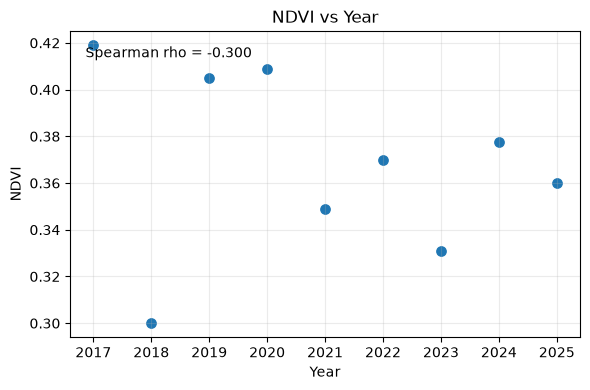

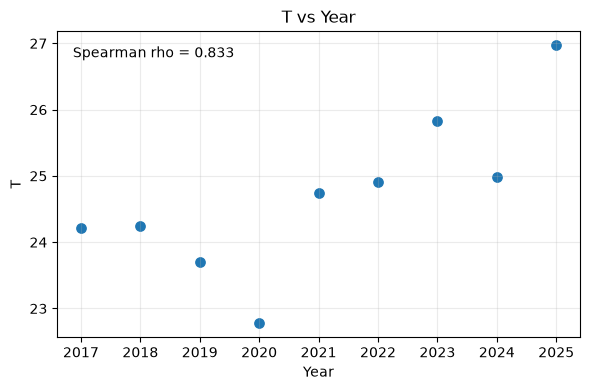

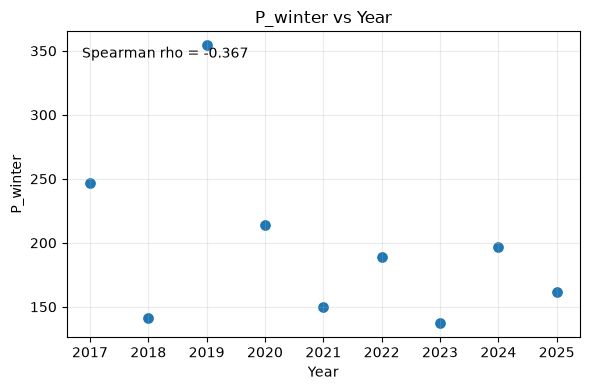

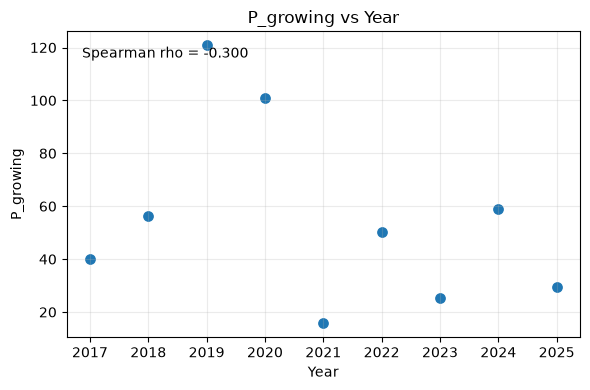

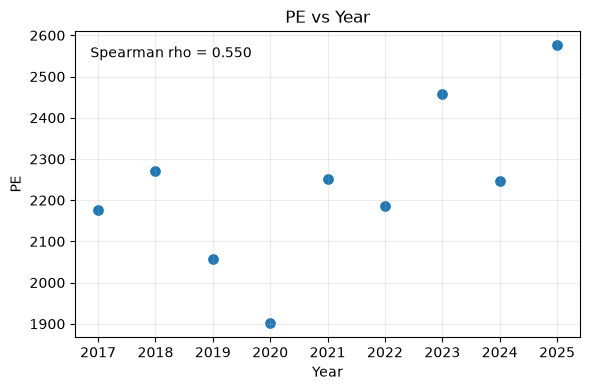

In [53]:
# ============================================================
# PHASE 12 — Baseline temporal analysis
# Spearman correlation with year
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ------------------------------------------------------------
# Variables for the baseline check
# ------------------------------------------------------------

baseline_vars = [
    "NDVI",
    "T",
    "P_winter",
    "P_growing",
    "PE"
]

# ------------------------------------------------------------
# Calculate Spearman rho with year
# No p-values are calculated at this stage.
# ------------------------------------------------------------

baseline_results = []

for var in baseline_vars:

    rho = spearmanr(
        climate_ndvi["year"],
        climate_ndvi[var]
    ).statistic

    baseline_results.append({
        "variable": var,
        "rho_year": rho
    })

baseline_results = pd.DataFrame(baseline_results)

# ------------------------------------------------------------
# Direction of NDVI trend
# ------------------------------------------------------------

ndvi_rho = baseline_results.loc[
    baseline_results["variable"] == "NDVI",
    "rho_year"
].iloc[0]

baseline_results["same_sign_as_NDVI"] = (
    np.sign(baseline_results["rho_year"])
    == np.sign(ndvi_rho)
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("Baseline temporal associations:")
display(baseline_results)

# ------------------------------------------------------------
# Scatter plots
# ------------------------------------------------------------

for var in baseline_vars:

    rho = baseline_results.loc[
        baseline_results["variable"] == var,
        "rho_year"
    ].iloc[0]

    fig, ax = plt.subplots(figsize=(6, 4))

    ax.scatter(
        climate_ndvi["year"],
        climate_ndvi[var],
        s=45
    )

    ax.set_xlabel("Year")
    ax.set_ylabel(var)
    ax.set_title(f"{var} vs Year")

    ax.text(
        0.03,
        0.95,
        f"Spearman rho = {rho:.3f}",
        transform=ax.transAxes,
        verticalalignment="top"
    )

    ax.set_xticks(climate_ndvi["year"])
    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

In [54]:
# ============================================================
# PHASE 12 — Primary Climate–NDVI Associations
# Exact Spearman permutation test + Bonferroni correction
# ============================================================

import numpy as np
import pandas as pd
from itertools import permutations
from scipy.stats import rankdata, spearmanr


# ============================================================
# 1. Primary variables
# ============================================================

primary_vars = [
    "T",
    "P_winter",
    "P_growing"
]

alpha = 0.05
bonferroni_k = len(primary_vars)
alpha_bonf = alpha / bonferroni_k

print(f"Primary tests: {bonferroni_k}")
print(f"Bonferroni-adjusted alpha: {alpha_bonf:.4f}")


# ============================================================
# 2. Exact Spearman permutation function
# ============================================================

def exact_spearman_permutation(x, y):
    """
    Exact two-sided permutation test for Spearman's rho.

    All permutations are enumerated.
    Suitable for the current n = 9 dataset:
    9! = 362,880 permutations.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)

    x = x[mask]
    y = y[mask]

    n = len(x)

    # Observed Spearman rho
    rho_obs = spearmanr(x, y).statistic

    # Rank-transform the two variables
    x_rank = rankdata(x)
    y_rank = rankdata(y)

    # Center ranks
    x_centered = x_rank - x_rank.mean()
    y_centered = y_rank - y_rank.mean()

    denominator = np.sqrt(
        np.sum(x_centered ** 2) *
        np.sum(y_centered ** 2)
    )

    # All permutations of y-ranks
    perm_indices = np.array(
        list(permutations(range(n))),
        dtype=np.int16
    )

    perm_y = y_rank[perm_indices]

    # Center permuted y-ranks
    perm_y_centered = (
        perm_y - y_rank.mean()
    )

    # Spearman rho for every permutation
    null_rho = (
        perm_y_centered @ x_centered
    ) / denominator

    # Exact two-sided p-value
    p_exact = np.mean(
        np.abs(null_rho) >= abs(rho_obs)
    )

    return rho_obs, p_exact


# ============================================================
# 3. Run the three primary tests
# ============================================================

primary_results = []

for var in primary_vars:

    rho, p_exact = exact_spearman_permutation(
        climate_ndvi["NDVI"],
        climate_ndvi[var]
    )

    p_bonf = min(
        p_exact * bonferroni_k,
        1.0
    )

    primary_results.append({
        "comparison": f"NDVI vs {var}",
        "variable": var,
        "rho": rho,
        "p_exact": p_exact,
        "p_bonferroni": p_bonf,
        "alpha_bonferroni": alpha_bonf,
        "bonferroni_significant": (
            p_bonf < alpha
        )
    })


primary_results = pd.DataFrame(
    primary_results
)


# ============================================================
# 4. Display results
# ============================================================

print("\nPrimary climate–NDVI associations:")

display(
    primary_results
)


# ============================================================
# 5. Compact reporting table
# ============================================================

report_table = primary_results[
    [
        "comparison",
        "rho",
        "p_exact",
        "p_bonferroni",
        "bonferroni_significant"
    ]
].copy()

display(report_table)

Primary tests: 3
Bonferroni-adjusted alpha: 0.0167

Primary climate–NDVI associations:


,comparison,variable,rho,p_exact,p_bonferroni,alpha_bonferroni,bonferroni_significant
0,NDVI vs T,T,-0.550000,0.132777,0.398330,0.016667,False
1,NDVI vs P_winter,P_winter,0.933333,0.000750,0.002249,0.016667,True
2,NDVI vs P_growing,P_growing,0.500000,0.177662,0.532986,0.016667,False


,comparison,rho,p_exact,p_bonferroni,bonferroni_significant
0,NDVI vs T,-0.550000,0.132777,0.398330,False
1,NDVI vs P_winter,0.933333,0.000750,0.002249,True
2,NDVI vs P_growing,0.500000,0.177662,0.532986,False


In [55]:
# ============================================================
# PHASE 12 — Secondary exploratory association
# NDVI vs Potential Evaporation
# ============================================================

# Calculate exact Spearman rho and permutation p-value
rho_pe, p_pe = exact_spearman_permutation(
    climate_ndvi["NDVI"],
    climate_ndvi["PE"]
)

# Create a compact result table
pe_result = pd.DataFrame({
    "comparison": ["NDVI vs PE"],
    "rho": [rho_pe],
    "p_exact": [p_pe],
    "test_type": ["Uncorrected, exploratory"]
})

print("Secondary exploratory result:")
display(pe_result)

Secondary exploratory result:


,comparison,rho,p_exact,test_type
0,NDVI vs PE,-0.816667,0.010769,"Uncorrected, exploratory"


In [56]:
# ============================================================
# PHASE 12 — Climate intercorrelation matrix
# ============================================================

from scipy.stats import spearmanr
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Climate variables
# ------------------------------------------------------------

climate_vars = [
    "T",
    "P_winter",
    "P_growing",
    "PE",
    "WS",
    "RH",
    "RAD"
]

# ------------------------------------------------------------
# Spearman correlation matrix
# ------------------------------------------------------------

climate_corr = pd.DataFrame(
    index=climate_vars,
    columns=climate_vars,
    dtype=float
)

for var1 in climate_vars:
    for var2 in climate_vars:

        rho = spearmanr(
            climate_ndvi[var1],
            climate_ndvi[var2]
        ).statistic

        climate_corr.loc[var1, var2] = rho


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("Climate intercorrelation matrix (Spearman rho):")

display(
    climate_corr.round(3)
)

Climate intercorrelation matrix (Spearman rho):


,T,P_winter,P_growing,PE,WS,RH,RAD
T,1.000,-0.617,-0.600,0.850,0.883,-0.850,0.500
P_winter,-0.617,1.000,0.667,-0.833,-0.633,0.850,-0.533
P_growing,-0.600,0.667,1.000,-0.683,-0.517,0.783,-0.900
PE,0.850,-0.833,-0.683,1.000,0.833,-0.967,0.633
WS,0.883,-0.633,-0.517,0.833,1.000,-0.767,0.517
RH,-0.850,0.850,0.783,-0.967,-0.767,1.000,-0.717
RAD,0.500,-0.533,-0.900,0.633,0.517,-0.717,1.000


In [57]:
# ============================================================
# PHASE 12 — Sensitivity analysis: 2018–2025
# ============================================================

from scipy.stats import spearmanr
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Primary climate variables
# ------------------------------------------------------------

primary_vars = [
    "T",
    "P_winter",
    "P_growing"
]

# ------------------------------------------------------------
# Subset: 2018–2025
# ------------------------------------------------------------

sens_data = climate_ndvi[
    climate_ndvi["year"] >= 2018
].copy()

assert len(sens_data) == 8, \
    "Sensitivity dataset must contain exactly 8 years."

# ------------------------------------------------------------
# Calculate Spearman rho for 2018–2025
# ------------------------------------------------------------

sensitivity_results = []

for var in primary_vars:

    rho_sens = spearmanr(
        sens_data["NDVI"],
        sens_data[var]
    ).statistic

    rho_main = primary_results.loc[
        primary_results["variable"] == var,
        "rho"
    ].iloc[0]

    delta_rho = rho_sens - rho_main

    same_sign = (
        np.sign(rho_sens) == np.sign(rho_main)
    )

    robust = (
        same_sign and
        abs(delta_rho) < 0.20
    )

    sensitivity_results.append({
        "variable": var,
        "rho_2017_2025": rho_main,
        "rho_2018_2025": rho_sens,
        "delta_rho": delta_rho,
        "abs_delta_rho": abs(delta_rho),
        "same_sign": same_sign,
        "sensitivity_consistent": robust
    })

sensitivity_results = pd.DataFrame(
    sensitivity_results
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("Sensitivity analysis: 2018–2025")
display(
    sensitivity_results.round(3)
)

Sensitivity analysis: 2018–2025


,variable,rho_2017_2025,rho_2018_2025,delta_rho,abs_delta_rho,same_sign,sensitivity_consistent
0,T,-0.550,-0.429,0.121,0.121,True,True
1,P_winter,0.933,0.952,0.019,0.019,True,True
2,P_growing,0.500,0.714,0.214,0.214,True,False


In [58]:
# ============================================================
# PHASE 12 — Leave-one-year-out sensitivity
# Primary climate–NDVI associations
# ============================================================

from scipy.stats import spearmanr
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Primary variables
# ------------------------------------------------------------

primary_vars = [
    "T",
    "P_winter",
    "P_growing"
]

years = climate_ndvi["year"].tolist()

loo_results = []

# ------------------------------------------------------------
# Remove one year at a time
# ------------------------------------------------------------

for excluded_year in years:

    subset = climate_ndvi[
        climate_ndvi["year"] != excluded_year
    ].copy()

    for var in primary_vars:

        rho = spearmanr(
            subset["NDVI"],
            subset[var]
        ).statistic

        loo_results.append({
            "excluded_year": excluded_year,
            "variable": var,
            "rho": rho
        })

loo_results = pd.DataFrame(loo_results)

# ------------------------------------------------------------
# Summary of rho range
# ------------------------------------------------------------

loo_summary = (
    loo_results
    .groupby("variable")["rho"]
    .agg(
        min_rho="min",
        max_rho="max"
    )
    .reset_index()
)

loo_summary["rho_range"] = (
    loo_summary["max_rho"]
    - loo_summary["min_rho"]
)

# ------------------------------------------------------------
# Check sign changes
# ------------------------------------------------------------

sign_summary = []

for var in primary_vars:

    values = loo_results.loc[
        loo_results["variable"] == var,
        "rho"
    ]

    sign_change = (
        values.min() < 0 and values.max() > 0
    )

    sign_summary.append({
        "variable": var,
        "sign_changes": sign_change
    })

sign_summary = pd.DataFrame(sign_summary)

loo_summary = pd.merge(
    loo_summary,
    sign_summary,
    on="variable",
    how="left"
)

# ------------------------------------------------------------
# Display detailed results
# ------------------------------------------------------------

print("Leave-one-year-out Spearman rho:")
display(
    loo_results.pivot(
        index="excluded_year",
        columns="variable",
        values="rho"
    ).round(3)
)

print("\nLeave-one-year-out summary:")
display(
    loo_summary.round(3)
)

Leave-one-year-out Spearman rho:


variable,P_growing,P_winter,T
excluded_year,,,
2017,0.714,0.952,-0.429
2018,0.714,0.929,-0.714
2019,0.429,0.976,-0.405
2020,0.429,0.952,-0.405
2021,0.429,0.905,-0.643
2022,0.500,0.905,-0.571
2023,0.429,0.929,-0.524
2024,0.405,0.905,-0.571
2025,0.405,0.905,-0.595



Leave-one-year-out summary:


,variable,min_rho,max_rho,rho_range,sign_changes
0,P_growing,0.405,0.714,0.310,False
1,P_winter,0.905,0.976,0.071,False
2,T,-0.714,-0.405,0.310,False


In [59]:
# ============================================================
# PHASE 12 — Final diagnostics
#
# 1. 2017–2018 NDVI transition by 2018 crop class
# 2. CV recalculation using the common-season NDVI metric
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path


# ============================================================
# PART 1 — Find the original 2018 field CSV
# ============================================================

data_dir = Path.cwd()

csv_candidates = []

for file in data_dir.glob("*.csv"):

    try:
        test_df = pd.read_csv(file, nrows=5)

        if (
            "system:index" in test_df.columns
            and "label_1" in test_df.columns
            and "year" in test_df.columns
        ):
            csv_candidates.append(file)

    except Exception:
        pass


print("Candidate field CSV files:")

for file in csv_candidates:
    print(" -", file.name)


# Find the file corresponding to year 2018
crop_file = None

for file in csv_candidates:

    try:
        test_df = pd.read_csv(file)

        if (
            len(test_df) > 0
            and 2018 in test_df["year"].astype(int).unique()
            and len(test_df) == 426
        ):
            crop_file = file
            break

    except Exception:
        pass


if crop_file is None:
    raise FileNotFoundError(
        "Could not identify the original 2018 field CSV."
    )


print(
    f"\nUsing 2018 field CSV: {crop_file.name}"
)


# ============================================================
# PART 2 — Extract 2018 crop labels
# ============================================================

crop_source = pd.read_csv(crop_file)

crop_labels = crop_source[
    [
        "system:index",
        "label_1"
    ]
].copy()

crop_labels = crop_labels.rename(
    columns={
        "system:index": "field_id",
        "label_1": "crop_label_2018"
    }
)

crop_labels["field_id"] = (
    crop_labels["field_id"]
    .astype(str)
)

crop_labels["crop_label_2018"] = (
    crop_labels["crop_label_2018"]
    .astype(str)
    .str.lower()
)

# Check unique field IDs
assert crop_labels["field_id"].is_unique, \
    "2018 crop labels contain duplicate field IDs."

assert len(crop_labels) == 426, \
    "Expected 426 crop-labeled fields."


# ============================================================
# PART 3 — Build 2017–2018 common-season NDVI
# ============================================================

common_months = [4, 6, 7, 8, 9, 10]

ndvi_1718_long = field_monthly_long[
    field_monthly_long["month"].isin(common_months)
    & field_monthly_long["year"].isin([2017, 2018])
].copy()

ndvi_1718_long["field_id"] = (
    ndvi_1718_long["field_id"]
    .astype(str)
)


# Field-year mean NDVI
field_year_ndvi_1718 = (
    ndvi_1718_long
    .groupby(
        ["field_id", "year"],
        as_index=False
    )["NDVI"]
    .mean()
    .rename(
        columns={
            "NDVI": "NDVI_common"
        }
    )
)


# Pivot to one row per field
ndvi_1718 = (
    field_year_ndvi_1718
    .pivot(
        index="field_id",
        columns="year",
        values="NDVI_common"
    )
    .reset_index()
)

ndvi_1718 = ndvi_1718.rename(
    columns={
        2017: "NDVI_2017",
        2018: "NDVI_2018"
    }
)


# ============================================================
# PART 4 — Attach 2018 crop labels
# ============================================================

ndvi_1718 = pd.merge(
    ndvi_1718,
    crop_labels,
    on="field_id",
    how="left",
    validate="one_to_one"
)


# Check merge
missing_crop_labels = (
    ndvi_1718["crop_label_2018"]
    .isna()
    .sum()
)

print(
    f"\nFields without crop label: {missing_crop_labels}"
)

assert missing_crop_labels == 0, \
    "Some fields are missing 2018 crop labels."

assert ndvi_1718["NDVI_2017"].notna().all()
assert ndvi_1718["NDVI_2018"].notna().all()


# ============================================================
# PART 5 — Group rare crop classes into Other
# ============================================================

main_classes = [
    "cotton",
    "wheat",
    "orchard"
]

ndvi_1718["crop_class"] = (
    ndvi_1718["crop_label_2018"]
    .where(
        ndvi_1718["crop_label_2018"].isin(main_classes),
        "Other"
    )
)


# ============================================================
# PART 6 — Calculate NDVI 2017 → 2018 transition
# ============================================================

ndvi_1718["lower_2018"] = (
    ndvi_1718["NDVI_2018"]
    < ndvi_1718["NDVI_2017"]
)


crop_transition = (
    ndvi_1718
    .groupby("crop_class")
    .agg(
        n_fields=("field_id", "size"),
        n_lower_2018=("lower_2018", "sum")
    )
    .reset_index()
)

crop_transition["pct_lower_2018"] = (
    100
    * crop_transition["n_lower_2018"]
    / crop_transition["n_fields"]
)

crop_transition = (
    crop_transition
    .sort_values(
        "n_fields",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n2017 → 2018 NDVI transition by 2018 crop class:"
)

display(
    crop_transition.round({
        "pct_lower_2018": 2
    })
)


# Overall percentage
overall_lower = (
    ndvi_1718["lower_2018"].mean()
    * 100
)

print(
    f"\nOverall percentage of fields with lower NDVI "
    f"in 2018: {overall_lower:.2f}%"
)


# ============================================================
# PART 7 — CV recalculation using common-season NDVI
# ============================================================
#
# Common months:
# April, June, July, August, September, October
#
# For each field:
#   CV = standard deviation / mean
#
# Threshold:
#   75th percentile of field-level CV
# ============================================================

ndvi_all_common = field_monthly_long[
    field_monthly_long["month"].isin(common_months)
].copy()


# Field-year common-season mean
field_year_ndvi_common = (
    ndvi_all_common
    .groupby(
        ["field_id", "year"],
        as_index=False
    )["NDVI"]
    .mean()
    .rename(
        columns={
            "NDVI": "NDVI_mean_common"
        }
    )
)


# Field-level mean and SD across years
field_cv_final = (
    field_year_ndvi_common
    .groupby("field_id")["NDVI_mean_common"]
    .agg(
        mean_ndvi="mean",
        sd_ndvi="std"
    )
    .reset_index()
)


# Coefficient of variation
field_cv_final["CV"] = (
    field_cv_final["sd_ndvi"]
    / field_cv_final["mean_ndvi"]
)


# 75th percentile threshold
cv_threshold = (
    field_cv_final["CV"]
    .quantile(0.75)
)


# Classification
field_cv_final["high_variability"] = (
    field_cv_final["CV"]
    >= cv_threshold
)


# Summary
n_fields = len(field_cv_final)

n_high = int(
    field_cv_final["high_variability"].sum()
)

n_other = (
    n_fields
    - n_high
)


print(
    "\nCV recalculation using NDVI_mean_common:"
)

print(
    f"Number of fields: {n_fields}"
)

print(
    f"75th percentile CV threshold: "
    f"{cv_threshold:.6f}"
)

print(
    f"High variability fields: {n_high}"
)

print(
    f"Remaining fields: {n_other}"
)


# ============================================================
# PART 8 — Final CV verification
# ============================================================

cv_check = pd.DataFrame({
    "metric": [
        "Number of fields",
        "CV threshold (75th percentile)",
        "High variability fields",
        "Remaining fields"
    ],
    "value": [
        n_fields,
        cv_threshold,
        n_high,
        n_other
    ]
})

print("\nCV verification:")

display(cv_check)

Candidate field CSV files:
 - Kashkadarya_Field_Indices_2017.csv
 - Kashkadarya_Field_Indices_2018.csv
 - Kashkadarya_Field_Indices_2019.csv
 - Kashkadarya_Field_Indices_2020.csv
 - Kashkadarya_Field_Indices_2021.csv
 - Kashkadarya_Field_Indices_2022.csv
 - Kashkadarya_Field_Indices_2023.csv
 - Kashkadarya_Field_Indices_2024.csv
 - Kashkadarya_Field_Indices_2025.csv

Using 2018 field CSV: Kashkadarya_Field_Indices_2017.csv

Fields without crop label: 0

2017 → 2018 NDVI transition by 2018 crop class:


,crop_class,n_fields,n_lower_2018,pct_lower_2018
0,cotton,221,148,66.97
1,wheat,177,170,96.05
2,orchard,15,14,93.33
3,Other,13,8,61.54



Overall percentage of fields with lower NDVI in 2018: 79.81%

CV recalculation using NDVI_mean_common:
Number of fields: 426
75th percentile CV threshold: 0.255638
High variability fields: 107
Remaining fields: 319

CV verification:


,metric,value
0,Number of fields,426.000000
1,CV threshold (75th percentile),0.255638
2,High variability fields,107.000000
3,Remaining fields,319.000000


In [60]:
print(field_monthly_long.columns.tolist())

['field_id', 'NDVI', 'NDMI', 'EVI', 'scene_count', 'year', 'month', 'low_obs', 'is_valid_month']


In [61]:
# ============================================================
# PHASE 12 — Correct 2017–2018 NDVI transition by 2018 crop
# ============================================================

# Exact 2018 field CSV
crop_file = Path.cwd() / "Kashkadarya_Field_Indices_2018.csv"

if not crop_file.exists():
    raise FileNotFoundError(
        f"2018 field CSV not found: {crop_file}"
    )

print(f"Using exact 2018 field CSV: {crop_file.name}")


# ------------------------------------------------------------
# Load 2018 crop labels
# ------------------------------------------------------------

crop_source_2018 = pd.read_csv(crop_file)

crop_labels_2018 = crop_source_2018[
    ["system:index", "label_1"]
].copy()

crop_labels_2018 = crop_labels_2018.rename(
    columns={
        "system:index": "field_id",
        "label_1": "crop_label_2018"
    }
)

crop_labels_2018["field_id"] = (
    crop_labels_2018["field_id"].astype(str)
)

crop_labels_2018["crop_label_2018"] = (
    crop_labels_2018["crop_label_2018"]
    .astype(str)
    .str.lower()
)

assert len(crop_labels_2018) == 426
assert crop_labels_2018["field_id"].is_unique


# ------------------------------------------------------------
# Build 2017 and 2018 common-season NDVI
# ------------------------------------------------------------

common_months = [4, 6, 7, 8, 9, 10]

ndvi_1718_long = field_monthly_long[
    field_monthly_long["month"].isin(common_months)
    & field_monthly_long["year"].isin([2017, 2018])
].copy()

ndvi_1718_long["field_id"] = (
    ndvi_1718_long["field_id"].astype(str)
)

field_year_ndvi_1718 = (
    ndvi_1718_long
    .groupby(
        ["field_id", "year"],
        as_index=False
    )["NDVI"]
    .mean()
    .rename(
        columns={"NDVI": "NDVI_common"}
    )
)

ndvi_1718 = (
    field_year_ndvi_1718
    .pivot(
        index="field_id",
        columns="year",
        values="NDVI_common"
    )
    .reset_index()
)

ndvi_1718 = ndvi_1718.rename(
    columns={
        2017: "NDVI_2017",
        2018: "NDVI_2018"
    }
)


# ------------------------------------------------------------
# Merge exact 2018 crop labels
# ------------------------------------------------------------

ndvi_1718 = pd.merge(
    ndvi_1718,
    crop_labels_2018,
    on="field_id",
    how="left",
    validate="one_to_one"
)

assert ndvi_1718["crop_label_2018"].notna().all()
assert ndvi_1718["NDVI_2017"].notna().all()
assert ndvi_1718["NDVI_2018"].notna().all()


# ------------------------------------------------------------
# Group rare crop classes into Other
# ------------------------------------------------------------

main_classes = [
    "cotton",
    "wheat",
    "orchard"
]

ndvi_1718["crop_class"] = (
    ndvi_1718["crop_label_2018"]
    .where(
        ndvi_1718["crop_label_2018"].isin(main_classes),
        "Other"
    )
)


# ------------------------------------------------------------
# Calculate 2017 → 2018 transition
# ------------------------------------------------------------

ndvi_1718["lower_2018"] = (
    ndvi_1718["NDVI_2018"]
    < ndvi_1718["NDVI_2017"]
)

crop_transition_corrected = (
    ndvi_1718
    .groupby("crop_class")
    .agg(
        n_fields=("field_id", "size"),
        n_lower_2018=("lower_2018", "sum")
    )
    .reset_index()
)

crop_transition_corrected["pct_lower_2018"] = (
    100
    * crop_transition_corrected["n_lower_2018"]
    / crop_transition_corrected["n_fields"]
)

crop_transition_corrected = (
    crop_transition_corrected
    .sort_values(
        "n_fields",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "Corrected 2017 → 2018 NDVI transition:"
)

display(
    crop_transition_corrected.round({
        "pct_lower_2018": 2
    })
)

overall_lower = (
    ndvi_1718["lower_2018"].mean() * 100
)

print(
    f"\nOverall percentage of fields with lower "
    f"NDVI in 2018: {overall_lower:.2f}%"
)

Using exact 2018 field CSV: Kashkadarya_Field_Indices_2018.csv
Corrected 2017 → 2018 NDVI transition:


,crop_class,n_fields,n_lower_2018,pct_lower_2018
0,cotton,221,148,66.97
1,wheat,177,170,96.05
2,orchard,15,14,93.33
3,Other,13,8,61.54



Overall percentage of fields with lower NDVI in 2018: 79.81%


In [62]:
# ============================================================
# PHASE 12 — Final Quality Control Summary
# ============================================================

import pandas as pd
import numpy as np

# ============================================================
# 1. Final annual dataset
# ============================================================

required_columns = [
    "year",
    "NDVI",
    "T",
    "P_winter",
    "P_growing",
    "PE",
    "WS",
    "RH",
    "RAD",
    "ERA5_n",
    "CHIRPS_n"
]

missing_columns = [
    col for col in required_columns
    if col not in climate_ndvi.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

assert climate_ndvi["year"].tolist() == list(range(2017, 2026))
assert len(climate_ndvi) == 9
assert climate_ndvi[required_columns].isna().sum().sum() == 0


# ============================================================
# 2. Primary results check
# ============================================================

assert len(primary_results) == 3
assert set(primary_results["variable"]) == {
    "T",
    "P_winter",
    "P_growing"
}


# ============================================================
# 3. Secondary PE result check
# ============================================================

assert len(pe_result) == 1
assert pe_result.loc[0, "test_type"] == (
    "Uncorrected, exploratory"
)


# ============================================================
# 4. Sensitivity check
# ============================================================

assert len(sensitivity_results) == 3
assert set(sensitivity_results["variable"]) == {
    "T",
    "P_winter",
    "P_growing"
}


# ============================================================
# 5. Leave-one-year-out check
# ============================================================

assert len(loo_results) == 27
assert len(loo_summary) == 3


# ============================================================
# 6. Crop transition check
# ============================================================

assert len(crop_transition_corrected) == 4
assert (
    crop_transition_corrected["n_fields"].sum()
    == 426
)


# ============================================================
# 7. CV check
# ============================================================

assert n_fields == 426
assert n_high == 107
assert n_other == 319

print("================================================")
print("PHASE 12 — FINAL QC")
print("================================================")

print("\nAnnual climate–NDVI records:", len(climate_ndvi))
print("Years:", climate_ndvi["year"].tolist())

print("\nMissing values: 0")
print("ERA5-Land cells:", climate_ndvi["ERA5_n"].unique())
print("CHIRPS cells:", climate_ndvi["CHIRPS_n"].unique())

print("\nPrimary tests:", len(primary_results))
print("Secondary PE test: available")
print("2018–2025 sensitivity: available")
print("Leave-one-year-out: available")
print("2017–2018 crop diagnostic: available")

print("\nCV threshold:", round(cv_threshold, 6))
print("High variability fields:", n_high)
print("Remaining fields:", n_other)

print("\nPHASE 12 STATUS: PASS")

PHASE 12 — FINAL QC

Annual climate–NDVI records: 9
Years: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

Missing values: 0
ERA5-Land cells: [2]
CHIRPS cells: [8]

Primary tests: 3
Secondary PE test: available
2018–2025 sensitivity: available
Leave-one-year-out: available
2017–2018 crop diagnostic: available

CV threshold: 0.255638
High variability fields: 107
Remaining fields: 319

PHASE 12 STATUS: PASS


In [63]:
# Save the final Phase 12 dataset for use in RStudio

output_file = "Kashkadarya_climate_NDVI_2017_2025.csv"

climate_ndvi.to_csv(
    output_file,
    index=False
)

print(f"Saved: {output_file}")

Saved: Kashkadarya_climate_NDVI_2017_2025.csv


In [64]:
print("annual_metrics_common" in globals())
print("field_cv_final" in globals())

True
True


In [65]:
print("annual_metrics_common columns:")
print(annual_metrics_common.columns.tolist())

print("\nfield_cv_final columns:")
print(field_cv_final.columns.tolist())

annual_metrics_common columns:
['field_id', 'year', 'NDVI_mean_gs_common', 'n_valid_months_common']

field_cv_final columns:
['field_id', 'mean_ndvi', 'sd_ndvi', 'CV', 'high_variability']


In [66]:
# Find existing objects related to trend, Mann-Kendall, classification, and crop data

keywords = [
    "trend",
    "slope",
    "sen",
    "mann",
    "mk",
    "kendall",
    "category",
    "class",
    "crop",
    "label"
]

matching_objects = sorted([
    name for name in globals()
    if any(key in name.lower() for key in keywords)
])

print("\n".join(matching_objects))

category_crop
category_crop_table
category_summary
category_summary_final
classify_field
crop
crop_counts_2018
crop_data
crop_file
crop_label_check
crop_labels
crop_labels_2018
crop_n
crop_profile
crop_source
crop_source_2018
crop_transition
crop_transition_corrected
cv_crop
cv_crop_summary
evi_slope
field_classification
field_classification_final
main_classes
major_crops
missing_crop_labels
mk
mk_result
month_labels
ndmi_slope
ndvi_slope
rho_sens
sen_result
sens_data
sensitivity_results
slope_by_crop
slope_check
slope_threshold
theilslopes
trend_common
trend_no2017
trend_results


In [67]:
objects_to_check = [
    "field_classification_final",
    "trend_common",
    "trend_results",
    "crop_labels_2018",
    "field_cv_final",
    "annual_metrics_common"
]

for obj_name in objects_to_check:
    obj = globals().get(obj_name)
    print(f"\n--- {obj_name} ---")
    
    if obj is None:
        print("NOT FOUND")
    elif hasattr(obj, "columns"):
        print(obj.columns.tolist())
        print("Shape:", obj.shape)
    else:
        print("Object type:", type(obj))


--- field_classification_final ---
['field_id', 'sen_slope_common', 'mk_p_common', 'q_value_common', 'significant_common', 'slope_threshold_met_common', 'CV', 'category']
Shape: (426, 8)

--- trend_common ---
['field_id', 'sen_slope_common', 'mk_p_common', 'q_value_common', 'significant_common', 'slope_threshold_met_common']
Shape: (426, 6)

--- trend_results ---
['field_id', 'sen_slope', 'mk_p', 'mk_trend', 'q_value', 'significant', 'slope_threshold_met']
Shape: (426, 7)

--- crop_labels_2018 ---
['field_id', 'crop_label_2018']
Shape: (426, 2)

--- field_cv_final ---
['field_id', 'mean_ndvi', 'sd_ndvi', 'CV', 'high_variability']
Shape: (426, 5)

--- annual_metrics_common ---
['field_id', 'year', 'NDVI_mean_gs_common', 'n_valid_months_common']
Shape: (3834, 4)


In [68]:
# ============================================================
# FINAL FIELD-LEVEL RESULTS EXPORT FOR QGIS
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# 1. Select final field-level analytical results
# ------------------------------------------------------------

field_results = field_classification_final[
    [
        "field_id",
        "cv",
        "sen_slope_common",
        "q_value_common",
        "category"
    ]
].copy()

field_results = field_results.rename(
    columns={
        "cv": "CV",
        "sen_slope_common": "sen_slope",
        "q_value_common": "mk_q"
    }
)


# ------------------------------------------------------------
# 2. Add 2018 reference crop labels
# ------------------------------------------------------------

crop_reference = crop_labels_2018[
    [
        "field_id",
        "crop_label_2018"
    ]
].copy()

field_results = field_results.merge(
    crop_reference,
    on="field_id",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 3. Add field area from the existing field-level dataset
# ------------------------------------------------------------

area_reference = (
    field_monthly_long[
        [
            "field_id",
            "geom_area_m2"
        ]
    ]
    .drop_duplicates(subset=["field_id"])
    .rename(columns={"geom_area_m2": "area_m2"})
)

field_results = field_results.merge(
    area_reference,
    on="field_id",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 4. Arrange final columns
# ------------------------------------------------------------

field_results = field_results[
    [
        "field_id",
        "CV",
        "sen_slope",
        "mk_q",
        "category",
        "crop_label_2018",
        "area_m2"
    ]
]


# ------------------------------------------------------------
# 5. Final integrity checks
# ------------------------------------------------------------

assert len(field_results) == 426, (
    f"Expected 426 fields, got {len(field_results)}"
)

assert field_results["field_id"].nunique() == 426, (
    "field_id is not unique."
)

assert field_results[
    [
        "field_id",
        "CV",
        "sen_slope",
        "mk_q",
        "category",
        "crop_label_2018",
        "area_m2"
    ]
].notna().all().all(), (
    "One or more required fields contain NULL values."
)


# ------------------------------------------------------------
# 6. Export final QGIS table
# ------------------------------------------------------------

output_file = "Kashkadarya_field_level_results_for_QGIS.csv"

field_results.to_csv(
    output_file,
    index=False
)

print("Final QGIS table created successfully.")
print(f"Rows: {len(field_results)}")
print(f"Columns: {len(field_results.columns)}")
print("\nColumns:")
print(field_results.columns.tolist())
print(f"\nSaved to:\n{os.path.abspath(output_file)}")

KeyError: "['cv'] not in index"

In [69]:
print(field_classification_final.columns.tolist())

['field_id', 'sen_slope_common', 'mk_p_common', 'q_value_common', 'significant_common', 'slope_threshold_met_common', 'CV', 'category']


In [70]:
print("--- crop_labels_2018 ---")
print(crop_labels_2018.columns.tolist())
print("Shape:", crop_labels_2018.shape)

print("\n--- field_monthly_long ---")
print(field_monthly_long.columns.tolist())
print("Shape:", field_monthly_long.shape)

--- crop_labels_2018 ---
['field_id', 'crop_label_2018']
Shape: (426, 2)

--- field_monthly_long ---
['field_id', 'NDVI', 'NDMI', 'EVI', 'scene_count', 'year', 'month', 'low_obs', 'is_valid_month']
Shape: (46008, 9)


In [71]:
# Find existing objects that may contain field geometry/area information

area_related_objects = []

for name, obj in globals().items():
    if any(key in name.lower() for key in ["area", "geo", "geometry", "field"]):
        if hasattr(obj, "columns"):
            cols = [str(c) for c in obj.columns]
            if any(
                key in col.lower()
                for col in cols
                for key in ["area", "geo", "geometry"]
            ):
                area_related_objects.append(
                    (name, obj.shape, cols)
                )

for item in area_related_objects:
    print("\nObject:", item[0])
    print("Shape:", item[1])
    print("Columns:", item[2])

RuntimeError: dictionary changed size during iteration

In [72]:
import os
import glob

csv_files = glob.glob("**/*.csv", recursive=True)

for f in csv_files:
    print(f)

Kashkadarya_CHIRPS_Precipitation_2017_2025.csv
Kashkadarya_climate_NDVI_2017_2025.csv
Kashkadarya_climate_NDVI_2017_2025_R.csv
Kashkadarya_ERA5Land_Climate_2017_2025.csv
Kashkadarya_Field_Indices_2017.csv
Kashkadarya_Field_Indices_2018.csv
Kashkadarya_Field_Indices_2019.csv
Kashkadarya_Field_Indices_2020.csv
Kashkadarya_Field_Indices_2021.csv
Kashkadarya_Field_Indices_2022.csv
Kashkadarya_Field_Indices_2023.csv
Kashkadarya_Field_Indices_2024.csv
Kashkadarya_Field_Indices_2025.csv


In [73]:
# Check the final 2017 GEE field file

df_2017 = pd.read_csv("Kashkadarya_Field_Indices_2017.csv")

print("Shape:", df_2017.shape)
print("\nColumns:")
print(df_2017.columns.tolist())

print("\nKey columns present:")
print("system:index" in df_2017.columns)
print(".geo" in df_2017.columns)
print("area" in df_2017.columns)

Shape: (426, 60)

Columns:
['system:index', 'area', 'country', 'date', 'label_1', 'label_2', 'm01_EVI', 'm01_NDMI', 'm01_NDVI', 'm01_scene_count', 'm02_EVI', 'm02_NDMI', 'm02_NDVI', 'm02_scene_count', 'm03_EVI', 'm03_NDMI', 'm03_NDVI', 'm03_scene_count', 'm04_EVI', 'm04_NDMI', 'm04_NDVI', 'm04_scene_count', 'm05_EVI', 'm05_NDMI', 'm05_NDVI', 'm05_scene_count', 'm06_EVI', 'm06_NDMI', 'm06_NDVI', 'm06_scene_count', 'm07_EVI', 'm07_NDMI', 'm07_NDVI', 'm07_scene_count', 'm08_EVI', 'm08_NDMI', 'm08_NDVI', 'm08_scene_count', 'm09_EVI', 'm09_NDMI', 'm09_NDVI', 'm09_scene_count', 'm10_EVI', 'm10_NDMI', 'm10_NDVI', 'm10_scene_count', 'm11_EVI', 'm11_NDMI', 'm11_NDVI', 'm11_scene_count', 'm12_EVI', 'm12_NDMI', 'm12_NDVI', 'm12_scene_count', 'observation_year', 'reference_year', 'region', 'sampler', 'year', '.geo']

Key columns present:
True
True
True


In [75]:
# ============================================================
# FINAL FIELD-LEVEL GEOPACKAGE FOR QGIS
# ============================================================

import json
import os
import pandas as pd
import geopandas as gpd
from shapely.geometry import shape


# ------------------------------------------------------------
# 1. Load the 2017 GEE field file
# ------------------------------------------------------------

df_2017 = pd.read_csv(
    "Kashkadarya_Field_Indices_2017.csv"
)

print("2017 GEE file:")
print("Rows:", len(df_2017))
print("Columns:", len(df_2017.columns))


# ------------------------------------------------------------
# 2. Parse GEE geometry
# ------------------------------------------------------------

def parse_geometry(value):
    if isinstance(value, dict):
        return shape(value)

    if isinstance(value, str):
        return shape(json.loads(value))

    raise ValueError("Unsupported geometry format.")


geometry = df_2017[".geo"].apply(parse_geometry)


# ------------------------------------------------------------
# 3. Create spatial field layer
# ------------------------------------------------------------

fields_gdf = gpd.GeoDataFrame(
    df_2017[
        [
            "system:index",
            "sampler",
            "country",
            "region",
            "date",
            "year",
            "label_1",
            "label_2",
            "area"
        ]
    ].copy(),
    geometry=geometry,
    crs="EPSG:4326"
)

fields_gdf = fields_gdf.rename(
    columns={
        "system:index": "field_id",
        "area": "source_area_m2"
    }
)


# ------------------------------------------------------------
# 4. Transform to final working CRS
# ------------------------------------------------------------

fields_gdf = fields_gdf.to_crs(
    "EPSG:32642"
)


# ------------------------------------------------------------
# 5. Calculate geometry-based area
# ------------------------------------------------------------

fields_gdf["area_m2"] = fields_gdf.geometry.area


# ------------------------------------------------------------
# 6. Select final field-level analytical results
# ------------------------------------------------------------

field_results = field_classification_final[
    [
        "field_id",
        "CV",
        "sen_slope_common",
        "q_value_common",
        "category"
    ]
].copy()

field_results = field_results.rename(
    columns={
        "sen_slope_common": "sen_slope",
        "q_value_common": "mk_q"
    }
)


# ------------------------------------------------------------
# 7. Select 2018 crop reference labels
# ------------------------------------------------------------

crop_reference = crop_labels_2018[
    [
        "field_id",
        "crop_label_2018"
    ]
].copy()


# ------------------------------------------------------------
# 8. Validate uniqueness
# ------------------------------------------------------------

assert fields_gdf["field_id"].nunique() == 426
assert field_results["field_id"].nunique() == 426
assert crop_reference["field_id"].nunique() == 426


# ------------------------------------------------------------
# 9. Join analytical results
# ------------------------------------------------------------

final_gdf = fields_gdf.merge(
    field_results,
    on="field_id",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 10. Join 2018 crop reference labels
# ------------------------------------------------------------

final_gdf = final_gdf.merge(
    crop_reference,
    on="field_id",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 11. Final integrity checks
# ------------------------------------------------------------

assert len(final_gdf) == 426
assert final_gdf["field_id"].nunique() == 426

required_fields = [
    "CV",
    "sen_slope",
    "mk_q",
    "category",
    "crop_label_2018",
    "area_m2"
]

for column in required_fields:
    missing = final_gdf[column].isna().sum()
    assert missing == 0, (
        f"{column} contains {missing} missing values."
    )


# ------------------------------------------------------------
# 12. Compare geometry area with original GEE area
# ------------------------------------------------------------

final_gdf["area_difference_pct"] = (
    abs(
        final_gdf["area_m2"]
        - final_gdf["source_area_m2"]
    )
    / final_gdf["source_area_m2"]
    * 100
)

max_area_difference = (
    final_gdf["area_difference_pct"].max()
)

print("\nMaximum area difference (%):")
print(round(max_area_difference, 4))


# ------------------------------------------------------------
# 13. Remove temporary QC column
# ------------------------------------------------------------

final_gdf = final_gdf.drop(
    columns=["area_difference_pct"]
)


# ------------------------------------------------------------
# 14. Final column order
# ------------------------------------------------------------

final_gdf = final_gdf[
    [
        "field_id",
        "CV",
        "sen_slope",
        "mk_q",
        "category",
        "crop_label_2018",
        "area_m2",
        "sampler",
        "country",
        "region",
        "date",
        "year",
        "label_1",
        "label_2",
        "source_area_m2",
        "geometry"
    ]
]


# ------------------------------------------------------------
# 15. Save permanent GeoPackage
# ------------------------------------------------------------

output_gpkg = (
    "Kashkadarya_field_level_results.gpkg"
)

final_gdf.to_file(
    output_gpkg,
    layer="field_level_results",
    driver="GPKG"
)


# ------------------------------------------------------------
# 16. Final confirmation
# ------------------------------------------------------------

print("\nFINAL QGIS GEOPACKAGE CREATED")
print("--------------------------------")
print("Rows:", len(final_gdf))
print("Unique field IDs:", final_gdf["field_id"].nunique())
print("CRS:", final_gdf.crs)
print("Output:", os.path.abspath(output_gpkg))

print("\nFinal analytical fields:")
print([
    "field_id",
    "CV",
    "sen_slope",
    "mk_q",
    "category",
    "crop_label_2018",
    "area_m2"
])

2017 GEE file:
Rows: 426
Columns: 60

Maximum area difference (%):
0.5985

FINAL QGIS GEOPACKAGE CREATED
--------------------------------
Rows: 426
Unique field IDs: 426
CRS: EPSG:32642
Output: C:\Users\lenovo\Project_Kashkadarya_2026_fields_426\Kashkadarya_field_level_results.gpkg

Final analytical fields:
['field_id', 'CV', 'sen_slope', 'mk_q', 'category', 'crop_label_2018', 'area_m2']
